# Семинар 3. kNN и локальные методы

Главный режим работы: **сначала предскажите результат, затем запустите код и объясните наблюдение**.

Связываем всё в одну линию: **метрика → соседство → локальность → взвешивание → локальная регрессия → геометрия выборки**.


## Оглавление

1. [Геометрия расстояний](#geometry)
   - [1.1. Метрика Минковского](#geometry)
   - [1.2. Косинусное расстояние](#cosine)
   - [1.3. Расстояние Махаланобиса](#mahalanobis)
2. [kNN-классификация](#knn-classification)
   - [2.1. Данные и базовый классификатор](#knn-classification)
   - [2.2. Механика предсказания](#knn-prediction)
   - [2.3. Влияние `k`](#knn-k)
   - [2.4. Подбор `k`](#knn-k-selection)
   - [2.5. Метрики расстояния](#knn-metrics)
   - [2.6. `StandardScaler`](#knn-scaling)
   - [2.7. Взвешенный kNN](#weighted-knn)
3. [Ядерные и локально-взвешенные методы](#kernels)
   - [3.1. От соседства к ядрам](#kernels)
   - [3.2. Окна Парзена](#parzen)
   - [3.3. Ядерная классификация](#kernel-classification)
4. [Локальная регрессия](#local-regression)
   - [4.1. kNN-регрессия](#knn-regression)
   - [4.2. Надарая–Ватсон](#nadaraya-watson)
   - [4.3. Ширина окна `h`](#bandwidth)
   - [4.4. Подбор `h`](#bandwidth-selection)
   - [4.5. LOWESS](#lowess)
5. [Дисбаланс классов и очистка границы](#imbalance)
   - [5.1. SMOTE](#imbalance)
   - [5.2. Tomek Links](#tomek)
   - [5.3. Очистка мажоритарного класса](#tomek-cleanup)
   - [5.4. SMOTE + Tomek](#smote-tomek)
6. [Домашняя практика](#homework)
   - [6.1. Задания на выбор](#homework)
   - [6.2. Требования к выполнению](#homework-rules)
7. [Итог](#summary)


In [1]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

<a id="geometry"></a>
## 1. Геометрия расстояний

### 1.1. Метрика Минковского

**До запуска:** как изменится расстояние Минковского при росте `p` от 1 к `∞`, и какая координата будет влиять сильнее?


In [3]:
def minkowski_distance(x1, x2, p=2):
    if p == np.inf:
        return np.max(np.abs(x1 - x2))
    else:
        return np.sum(np.abs(x1 - x2) ** p) ** (1/p)

np.random.seed(123)
x1 = np.random.randn(5)
x2 = np.random.randn(5)

print("Пример точек:")
print(f"x1: {x1}")
print(f"x2: {x2}")
print()

p_values = [1, 2, 3, 5, np.inf]
for p in p_values:
    if p == np.inf:
        name = "Чебышева"
    elif p == 1:
        name = "Манхэттенское"
    elif p == 2:
        name = "Евклидово"
    else:
        name = f"Минковского (p={p})"

    distance = minkowski_distance(x1, x2, p)
    print(f"Расстояние {name}: {distance:.4f}")

Пример точек:
x1: [-1.0856306   0.99734545  0.2829785  -1.50629471 -0.57860025]
x2: [ 1.65143654 -2.42667924 -0.42891263  1.26593626 -0.8667404 ]

Расстояние Манхэттенское: 9.9334
Расстояние Евклидово: 5.2431
Расстояние Минковского (p=3): 4.3504
Расстояние Минковского (p=5): 3.7960
Расстояние Чебышева: 3.4240


<a id="cosine"></a>
### 1.2. Косинусное расстояние: направление вместо масштаба

Если два вектора сонаправлены, но один намного длиннее другого, как будут вести себя Euclidean distance и cosine similarity?


In [4]:
def cosine_similarity(x1, x2):
    dot_product = np.dot(x1, x2)
    norm_x1 = np.linalg.norm(x1)
    norm_x2 = np.linalg.norm(x2)

    if norm_x1 == 0 or norm_x2 == 0:
        return 0

    return dot_product / (norm_x1 * norm_x2)

def cosine_distance(x1, x2):
    return 1 - cosine_similarity(x1, x2)

print(f"Косинусное сходство: {cosine_similarity(x1, x2):.4f}")
print(f"Косинусное расстояние: {cosine_distance(x1, x2):.4f}")

Косинусное сходство: -0.7798
Косинусное расстояние: 1.7798


<a id="mahalanobis"></a>
### 1.3. Расстояние Махаланобиса: геометрия коррелированных признаков

Если признаки коррелированы и облако вытянуто по диагонали, почему Mahalanobis distance может описывать «необычность» смещения лучше Euclidean?


In [5]:
def mahalanobis_distance(x1, x2, cov_inv):
    diff = x1 - x2
    return np.sqrt(diff.T @ cov_inv @ diff)

np.random.seed(123)
n_samples = 100
n_features = 3
X = np.random.multivariate_normal(
    mean=[0, 0, 0],
    cov=[[1, 0.8, 0.5], [0.8, 1, 0.3], [0.5, 0.3, 1]],
    size=n_samples
)

cov_matrix = np.cov(X, rowvar=False)
cov_inv = np.linalg.inv(cov_matrix)

idx1, idx2 = np.random.choice(n_samples, 2, replace=False)
point1 = X[idx1]
point2 = X[idx2]

print(f"Точка 1: {point1}")
print(f"Точка 2: {point2}")
print(f"Расстояние Махаланобиса: {mahalanobis_distance(point1, point2, cov_inv):.4f}")
print(f"Евклидово расстояние: {minkowski_distance(point1, point2, 2):.4f}")

Точка 1: [ 0.63224097 -0.30115786  1.63910627]
Точка 2: [ 0.39277457  0.18574984 -0.88815116]
Расстояние Махаланобиса: 2.5206
Евклидово расстояние: 2.5849


<a id="knn-classification"></a>
## 2. kNN-классификация

### 2.1. Данные и базовый классификатор

Посмотрите на выборку: какие точки вы заранее считаете трудными для локального классификатора?


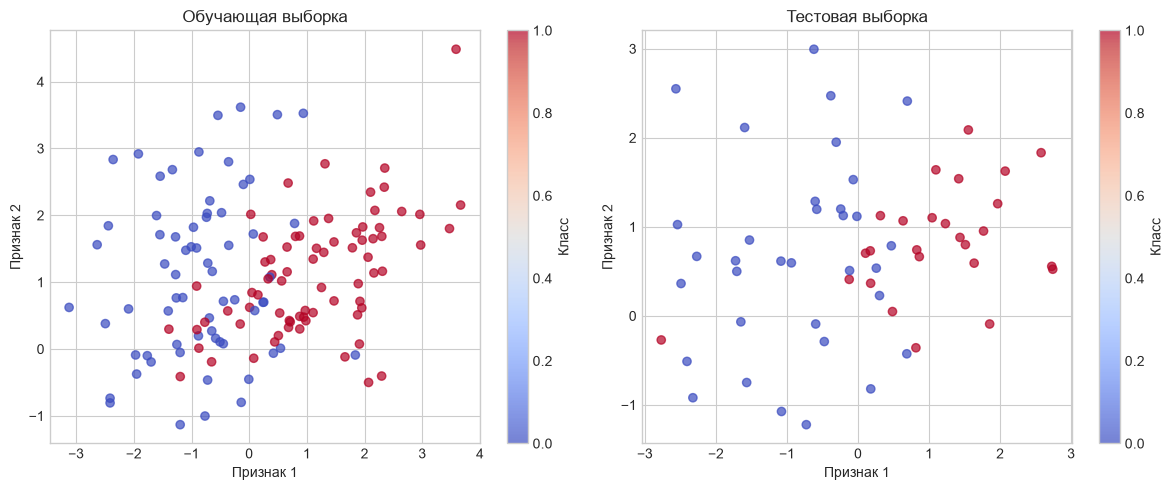

In [6]:
X, y = make_classification(
    n_samples=200,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', alpha=0.7)
plt.title('Обучающая выборка')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.colorbar(label='Класс')

plt.subplot(1, 2, 2)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', alpha=0.7)
plt.title('Тестовая выборка')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.colorbar(label='Класс')

plt.tight_layout()
plt.show()

<a id="knn-prediction"></a>
### 2.2. Механика предсказания kNN

Для одной новой точки сформулируйте алгоритм вручную: **расстояния → ближайшие соседи → их классы → голосование**.


In [7]:
class KNNClassifier:
    def __init__(self, k=5, distance_metric='euclidean', p=2):
        self.k = k
        self.distance_metric = distance_metric
        self.p = p
        self.X_train = None
        self.y_train = None

    def _compute_distance(self, x1, x2):
        if self.distance_metric == 'euclidean':
            return minkowski_distance(x1, x2, p=2)
        elif self.distance_metric == 'manhattan':
            return minkowski_distance(x1, x2, p=1)
        elif self.distance_metric == 'minkowski':
            return minkowski_distance(x1, x2, p=self.p)
        elif self.distance_metric == 'cosine':
            return cosine_distance(x1, x2)

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        return self

    def predict(self, X):
        predictions = []
        for x in X:
            distances = []
            for i, train_point in enumerate(self.X_train):
                dist = self._compute_distance(x, train_point)
                distances.append((dist, i))

            distances.sort(key=lambda x: x[0])
            k_nearest_indices = [idx for _, idx in distances[:self.k]]
            k_nearest_labels = self.y_train[k_nearest_indices]

            unique_labels, counts = np.unique(k_nearest_labels, return_counts=True)
            predicted_label = unique_labels[np.argmax(counts)]
            predictions.append(predicted_label)

        return np.array(predictions)

    def predict_proba(self, X):
        probabilities = []
        for x in X:
            distances = []
            for i, train_point in enumerate(self.X_train):
                dist = self._compute_distance(x, train_point)
                distances.append((dist, i))

            distances.sort(key=lambda x: x[0])
            k_nearest_indices = [idx for _, idx in distances[:self.k]]
            k_nearest_labels = self.y_train[k_nearest_indices]

            unique_labels, counts = np.unique(k_nearest_labels, return_counts=True)
            proba = np.zeros(len(unique_labels))
            for i, label in enumerate(unique_labels):
                proba[i] = np.sum(k_nearest_labels == label) / self.k

            probabilities.append(dict(zip(unique_labels, proba)))

        return probabilities

knn_custom = KNNClassifier(k=5, distance_metric='euclidean')
knn_custom.fit(X_train, y_train)
y_pred_custom = knn_custom.predict(X_test)

accuracy_custom = accuracy_score(y_test, y_pred_custom)
print(f"Точность нашей реализации kNN: {accuracy_custom:.4f}")

knn_sklearn = KNeighborsClassifier(n_neighbors=5)
knn_sklearn.fit(X_train, y_train)
y_pred_sklearn = knn_sklearn.predict(X_test)

accuracy_sklearn = accuracy_score(y_test, y_pred_sklearn)
print(f"Точность sklearn kNN: {accuracy_sklearn:.4f}")

Точность нашей реализации kNN: 0.8000
Точность sklearn kNN: 0.8000


<a id="knn-neighbors"></a>
#### 2.2.1. Одна query point и её ближайшие соседи

Посмотрим, какие объекты реально определяют предсказание kNN для одной query point.


<Figure size 900x700 with 0 Axes>

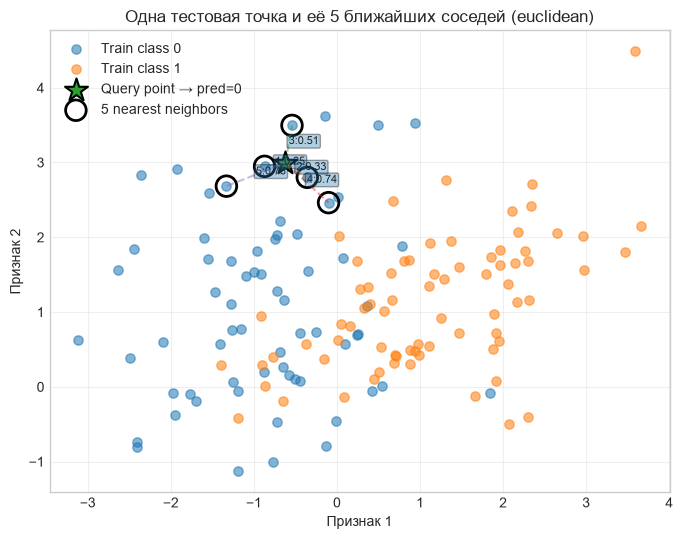

Истинный класс точки: 0
Предсказанный класс: 0
Классы соседей: [0 0 0 0 0]
Расстояния до соседей: [0.255 0.327 0.507 0.744 0.776]


In [8]:
def plot_query_with_neighbors(X_train, y_train, query_point, k=5, distance_metric='euclidean',
                              title=None, ax=None, show_distances=True):
    local_knn = KNNClassifier(k=k, distance_metric=distance_metric).fit(X_train, y_train)

    distances = []
    for i, train_point in enumerate(X_train):
        dist = local_knn._compute_distance(query_point, train_point)
        distances.append((dist, i))
    distances.sort(key=lambda x: x[0])

    neighbor_indices = [idx for _, idx in distances[:k]]
    neighbor_distances = [dist for dist, _ in distances[:k]]
    neighbor_labels = y_train[neighbor_indices]

    unique_labels, counts = np.unique(neighbor_labels, return_counts=True)
    pred_label = unique_labels[np.argmax(counts)]

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    class_0 = y_train == 0
    class_1 = y_train == 1

    ax.scatter(X_train[class_0, 0], X_train[class_0, 1],
               alpha=0.55, s=45, label='Train class 0')
    ax.scatter(X_train[class_1, 0], X_train[class_1, 1],
               alpha=0.55, s=45, label='Train class 1')

    ax.scatter(query_point[0], query_point[1],
               marker='*', s=300, edgecolors='k', linewidths=1.5,
               label=f'Query point → pred={pred_label}')

    ax.scatter(X_train[neighbor_indices, 0], X_train[neighbor_indices, 1],
               facecolors='none', edgecolors='k', s=220, linewidths=2,
               label=f'{k} nearest neighbors')

    for rank, (idx, dist) in enumerate(zip(neighbor_indices, neighbor_distances), start=1):
        x_n, y_n = X_train[idx]
        ax.plot([query_point[0], x_n], [query_point[1], y_n],
                linestyle='--', alpha=0.45)
        if show_distances:
            mid_x = (query_point[0] + x_n) / 2
            mid_y = (query_point[1] + y_n) / 2
            ax.text(mid_x, mid_y, f'{rank}:{dist:.2f}', fontsize=8,
                    bbox=dict(boxstyle='round,pad=0.15', alpha=0.35))

    if title is None:
        title = f'Одна тестовая точка и её {k} ближайших соседей ({distance_metric})'
    ax.set_title(title)
    ax.set_xlabel('Признак 1')
    ax.set_ylabel('Признак 2')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

    return neighbor_indices, neighbor_distances, pred_label

query_idx = 0
query_point = X_test[query_idx]

plt.figure(figsize=(9, 7))
neigh_idx, neigh_dist, pred_label = plot_query_with_neighbors(
    X_train, y_train, query_point, k=5, distance_metric='euclidean'
)
plt.show()

print(f"Истинный класс точки: {y_test[query_idx]}")
print(f"Предсказанный класс: {pred_label}")
print("Классы соседей:", y_train[neigh_idx])
print("Расстояния до соседей:", np.round(neigh_dist, 3))


<a id="knn-k"></a>
### 2.3. Влияние числа соседей `k`

**Прогноз:** как будет меняться decision boundary при росте `k`? Где ожидаете high variance, а где — сильное сглаживание?


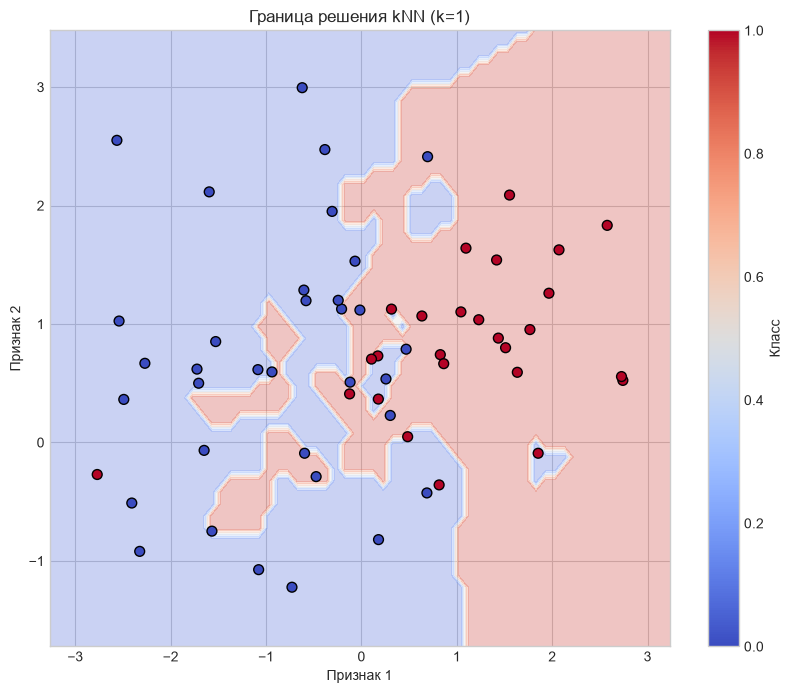

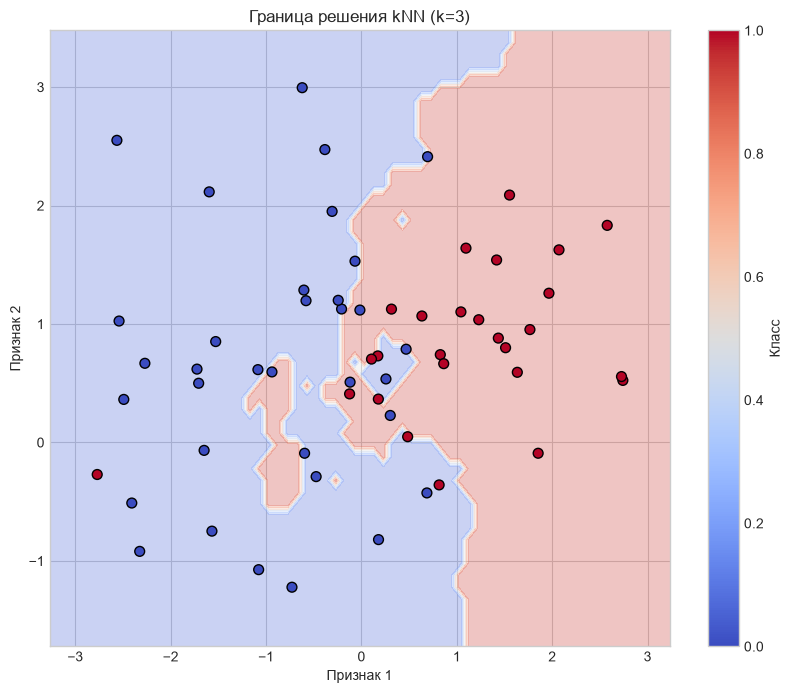

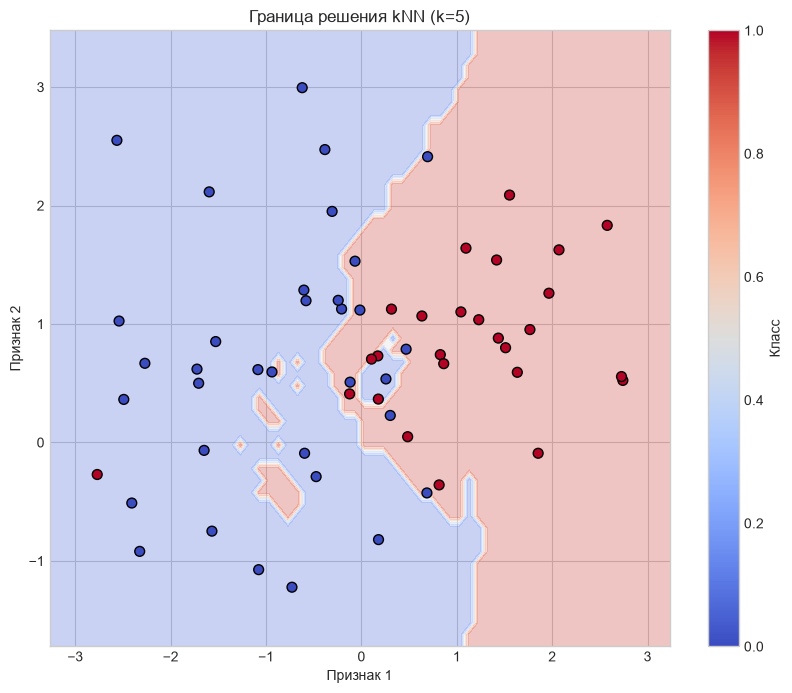

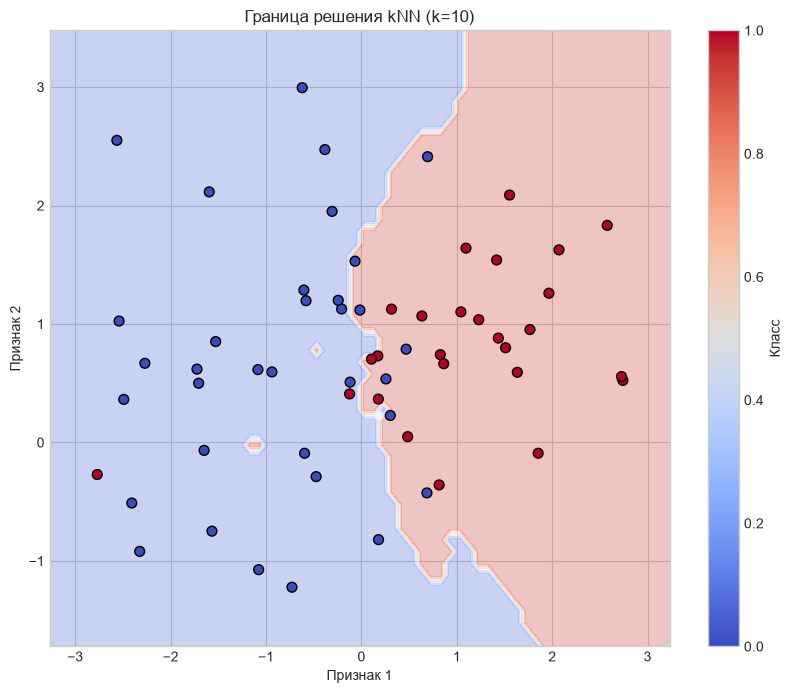

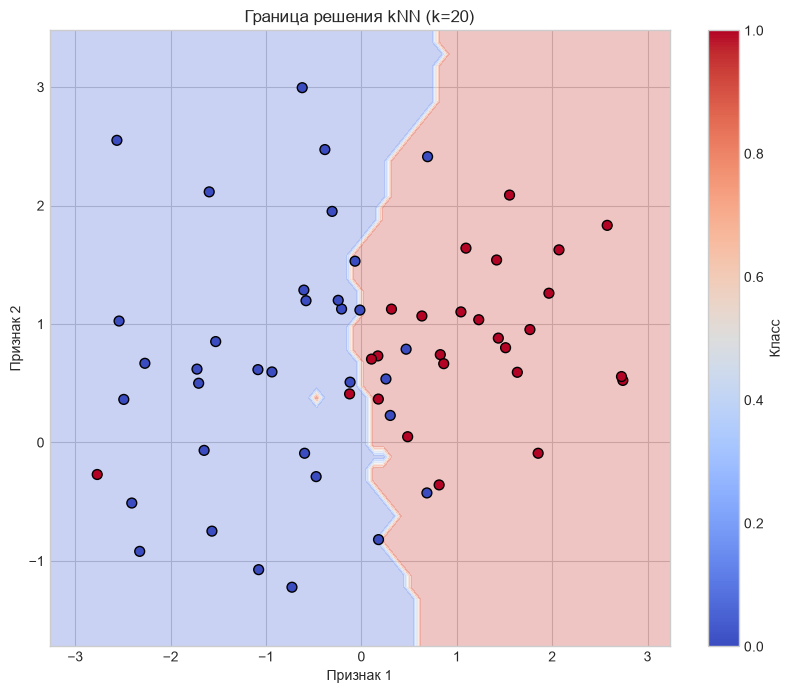

In [9]:
def plot_decision_boundary(model, X, y, title="Граница решения kNN", grid_step=0.10):
    h = grid_step
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(10, 8))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k', s=50)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(title)
    plt.xlabel('Признак 1')
    plt.ylabel('Признак 2')
    plt.colorbar(label='Класс')
    plt.show()

for k in [1, 3, 5, 10, 20]:
    knn = KNNClassifier(k=k, distance_metric='euclidean')
    knn.fit(X_train, y_train)
    plot_decision_boundary(knn, X_test, y_test, title=f"Граница решения kNN (k={k})")

<a id="knn-k-slider"></a>
#### 2.3.1. Интерактивная граница решения при разных `k`

Слайдер показывает, как граница меняется при плавном увеличении числа соседей.


In [10]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [11]:
def show_knn_boundary(k=5):
    knn = KNNClassifier(k=int(k), distance_metric='euclidean').fit(X_train, y_train)
    plot_decision_boundary(knn, X_test, y_test, title=f'Интерактивная граница kNN (k={int(k)})')

try:
    from ipywidgets import interact, IntSlider
    interact(show_knn_boundary, k=IntSlider(value=5, min=1, max=30, step=1, description='k'));
except Exception as e:
    print("ipywidgets недоступен, поэтому покажем статический пример.")
    print("Ошибка:", e)
    show_knn_boundary(5)


interactive(children=(IntSlider(value=5, description='k', max=30, min=1), Output()), _dom_classes=('widget-int…

<a id="knn-k-selection"></a>
### 2.4. Подбор `k` по validation
Небольшой эксперимент перед остальными методами: выбираем число соседей по отложенной выборке.


Лучшее k на validation: 3


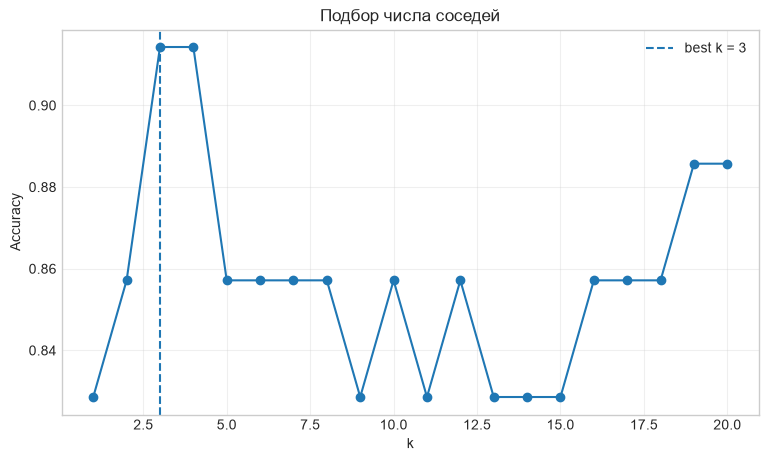

In [12]:
# Отделим validation от обучающей выборки
X_train_knn, X_val_knn, y_train_knn, y_val_knn = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42
)

k_values = range(1, 21)
val_scores = []

for k in k_values:
    model = KNNClassifier(k=k, distance_metric='euclidean')
    model.fit(X_train_knn, y_train_knn)
    y_pred = model.predict(X_val_knn)
    val_scores.append(accuracy_score(y_val_knn, y_pred))

best_k = list(k_values)[np.argmax(val_scores)]
print(f"Лучшее k на validation: {best_k}")

plt.figure(figsize=(9, 5))
plt.plot(k_values, val_scores, 'o-')
plt.axvline(best_k, linestyle='--', label=f'best k = {best_k}')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('Подбор числа соседей')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


<a id="knn-metrics"></a>
### 2.5. Выбор метрики расстояния

Будут ли Euclidean, Manhattan и cosine выбирать одних и тех же соседей для одной точки?


In [13]:
metrics = ['euclidean', 'manhattan', 'cosine']

for metric in metrics:
    knn_metric = KNNClassifier(k=5, distance_metric=metric)
    knn_metric.fit(X_train, y_train)
    y_pred_metric = knn_metric.predict(X_test)
    accuracy_metric = accuracy_score(y_test, y_pred_metric)
    print(f"Точность с метрикой '{metric}': {accuracy_metric:.4f}")

Точность с метрикой 'euclidean': 0.8000
Точность с метрикой 'manhattan': 0.8333
Точность с метрикой 'cosine': 0.8667


<a id="knn-metrics-visual"></a>
#### 2.5.1. Как метрика меняет ближайших соседей

Сравним ближайших соседей одной query point при Euclidean, Manhattan и cosine distance.


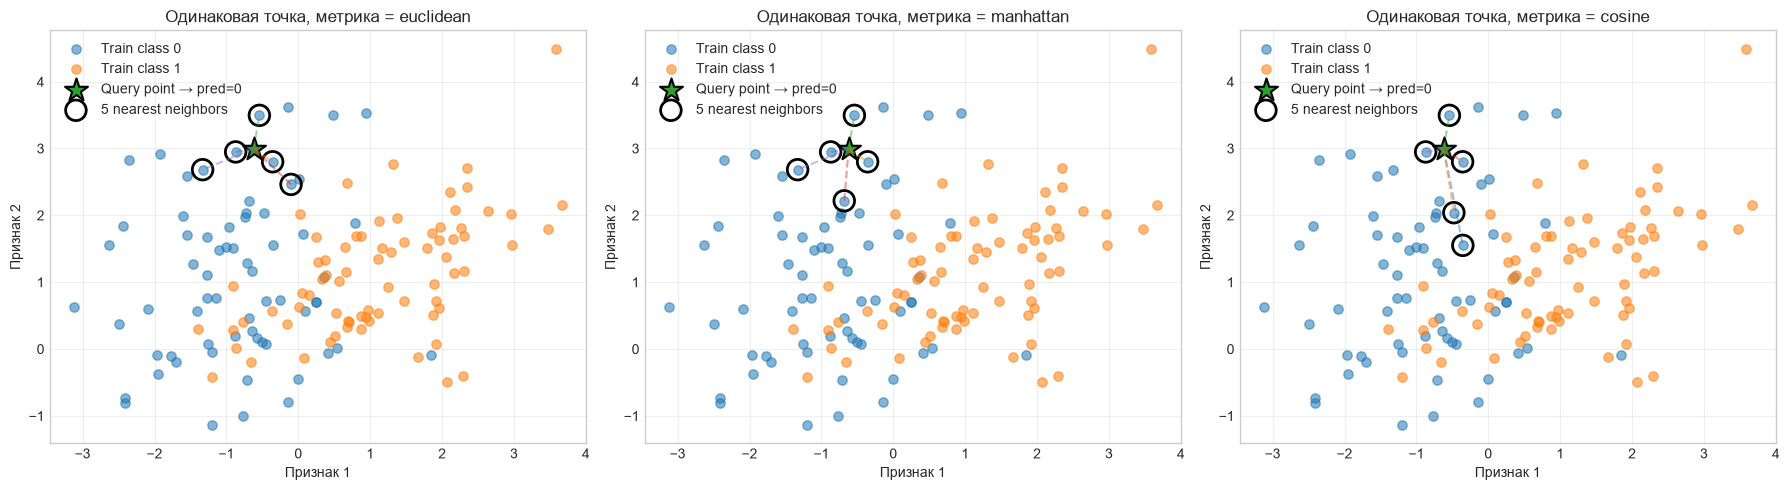

In [14]:
metrics_to_show = ['euclidean', 'manhattan', 'cosine']
query_point = X_test[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric in zip(axes, metrics_to_show):
    plot_query_with_neighbors(
        X_train, y_train, query_point, k=5, distance_metric=metric,
        title=f'Одинаковая точка, метрика = {metric}', ax=ax, show_distances=False
    )

plt.tight_layout()
plt.show()


<a id="knn-scaling"></a>
### 2.6. Масштабирование признаков: `StandardScaler`

Умножим один признак на `100`. Предскажите, как это изменит соседей и границу решения, затем сравним обычный kNN и kNN после `StandardScaler`.


Accuracy без scaling:       0.600
Accuracy со StandardScaler: 0.867


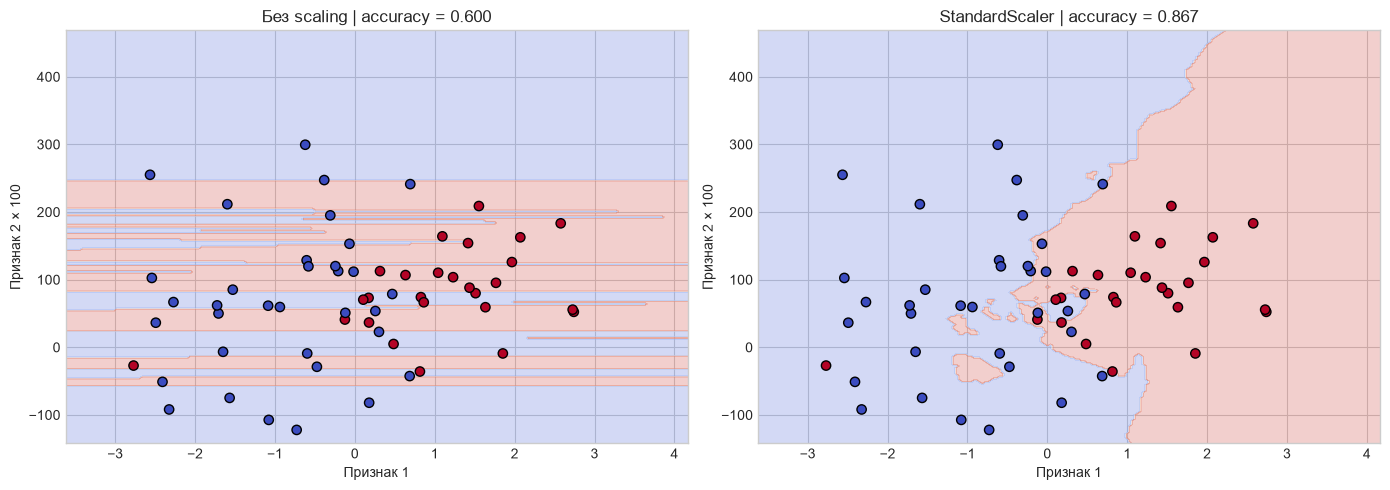

In [15]:
# Создадим искусственную проблему масштаба:
# второй признак выражен в единицах, делающих его значения в 100 раз крупнее.
X_scale_demo = X.copy()
X_scale_demo[:, 1] *= 100

X_train_scale, X_test_scale, y_train_scale, y_test_scale = train_test_split(
    X_scale_demo, y, test_size=0.3, random_state=42
)

# 1) kNN без масштабирования
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train_scale, y_train_scale)
raw_accuracy = accuracy_score(y_test_scale, knn_raw.predict(X_test_scale))

# 2) kNN после StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_scale)
X_test_scaled = scaler.transform(X_test_scale)

knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(X_train_scaled, y_train_scale)
scaled_accuracy = accuracy_score(
    y_test_scale,
    knn_scaled.predict(X_test_scaled)
)

print(f"Accuracy без scaling:       {raw_accuracy:.3f}")
print(f"Accuracy со StandardScaler: {scaled_accuracy:.3f}")

# Покажем обе decision boundary в исходных (искусственно искажённых) координатах.
x_min, x_max = X_scale_demo[:, 0].min() - 0.5, X_scale_demo[:, 0].max() + 0.5
y_min, y_max = X_scale_demo[:, 1].min() - 20, X_scale_demo[:, 1].max() + 20

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 220),
    np.linspace(y_min, y_max, 220)
)
grid = np.c_[xx.ravel(), yy.ravel()]

Z_raw = knn_raw.predict(grid).reshape(xx.shape)
Z_scaled = knn_scaled.predict(scaler.transform(grid)).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].contourf(xx, yy, Z_raw, alpha=0.25, cmap='coolwarm')
axes[0].scatter(
    X_test_scale[:, 0], X_test_scale[:, 1],
    c=y_test_scale, cmap='coolwarm', edgecolors='k', s=45
)
axes[0].set_title(f'Без scaling | accuracy = {raw_accuracy:.3f}')
axes[0].set_xlabel('Признак 1')
axes[0].set_ylabel('Признак 2 × 100')

axes[1].contourf(xx, yy, Z_scaled, alpha=0.25, cmap='coolwarm')
axes[1].scatter(
    X_test_scale[:, 0], X_test_scale[:, 1],
    c=y_test_scale, cmap='coolwarm', edgecolors='k', s=45
)
axes[1].set_title(f'StandardScaler | accuracy = {scaled_accuracy:.3f}')
axes[1].set_xlabel('Признак 1')
axes[1].set_ylabel('Признак 2 × 100')

plt.tight_layout()
plt.show()


<a id="weighted-knn"></a>
### 2.7. Взвешенный kNN
Ближайшие соседи могут иметь больший вес, чем дальние. Здесь делаем это напрямую через `1 / distance`.


Обычный kNN:    0.8000
Взвешенный kNN: 0.8000


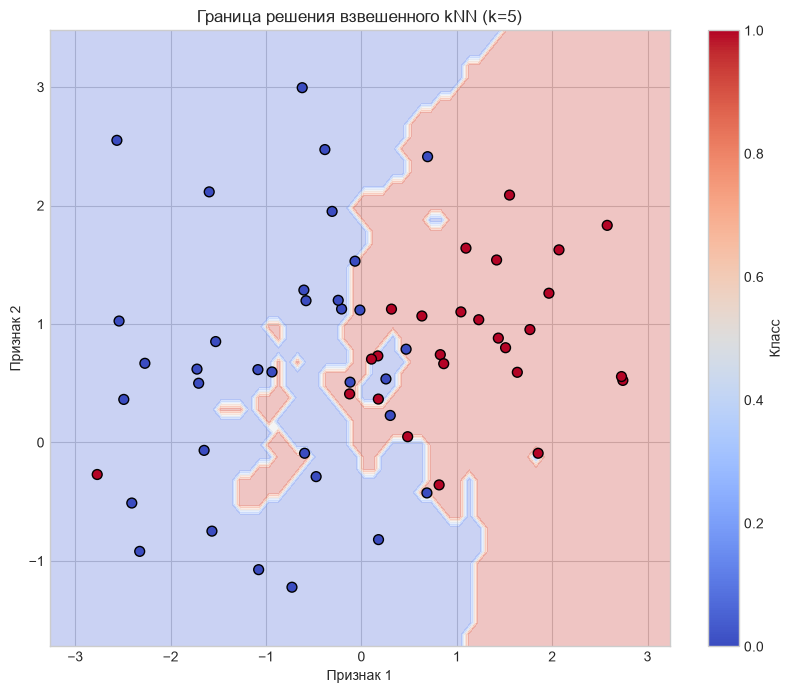

In [16]:
class WeightedKNNClassifier(KNNClassifier):
    def predict(self, X):
        predictions = []

        for x in X:
            distances = []
            for i, train_point in enumerate(self.X_train):
                dist = self._compute_distance(x, train_point)
                distances.append((dist, i))

            distances.sort(key=lambda z: z[0])
            nearest = distances[:self.k]

            class_scores = {}
            for dist, idx in nearest:
                label = self.y_train[idx]
                weight = 1 / (dist + 1e-9)
                class_scores[label] = class_scores.get(label, 0) + weight

            predictions.append(max(class_scores, key=class_scores.get))

        return np.array(predictions)

weighted_knn = WeightedKNNClassifier(k=5, distance_metric='euclidean')
weighted_knn.fit(X_train, y_train)
y_pred_weighted = weighted_knn.predict(X_test)

print(f"Обычный kNN:    {accuracy_custom:.4f}")
print(f"Взвешенный kNN: {accuracy_score(y_test, y_pred_weighted):.4f}")

plot_decision_boundary(weighted_knn, X_test, y_test,
                       title='Граница решения взвешенного kNN (k=5)')


<a id="kernels"></a>
## 3. Ядерные и локально-взвешенные методы

### 3.1. От жёсткого соседства к ядрам

В обычном kNN все выбранные соседи голосуют одинаково. Что изменится, если вес плавно уменьшать с расстоянием?


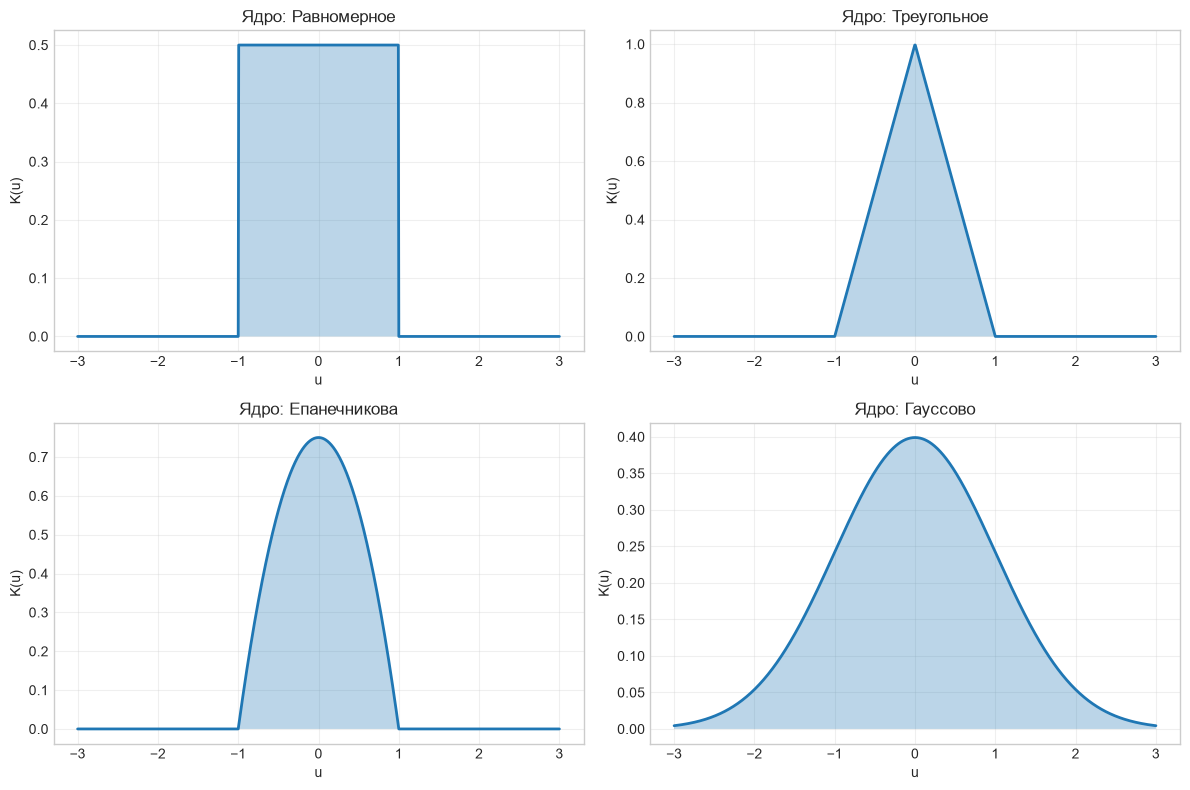

In [17]:
def uniform_kernel(u):
    return 0.5 if np.abs(u) < 1 else 0

def triangular_kernel(u):
    return (1 - np.abs(u)) if np.abs(u) < 1 else 0

def epanechnikov_kernel(u):
    return 0.75 * (1 - u**2) if np.abs(u) < 1 else 0

def gaussian_kernel(u):
    return np.exp(-0.5 * u**2) / np.sqrt(2 * np.pi)

x = np.linspace(-3, 3, 1000)
kernels = {
    'Равномерное': uniform_kernel,
    'Треугольное': triangular_kernel,
    'Епанечникова': epanechnikov_kernel,
    'Гауссово': gaussian_kernel
}

plt.figure(figsize=(12, 8))
for i, (name, kernel_func) in enumerate(kernels.items(), 1):
    # Не перезаписываем y: это метки классов из раздела классификации.
    kernel_values = np.array([kernel_func(xi) for xi in x])
    plt.subplot(2, 2, i)
    plt.plot(x, kernel_values, linewidth=2)
    plt.fill_between(x, kernel_values, alpha=0.3)
    plt.title(f'Ядро: {name}')
    plt.xlabel('u')
    plt.ylabel('K(u)')
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<a id="kernel-weights"></a>
#### 3.1.1. Как расстояние превращается в вес

Посмотрим, какой вес разные ядра дают реальным ближайшим объектам.


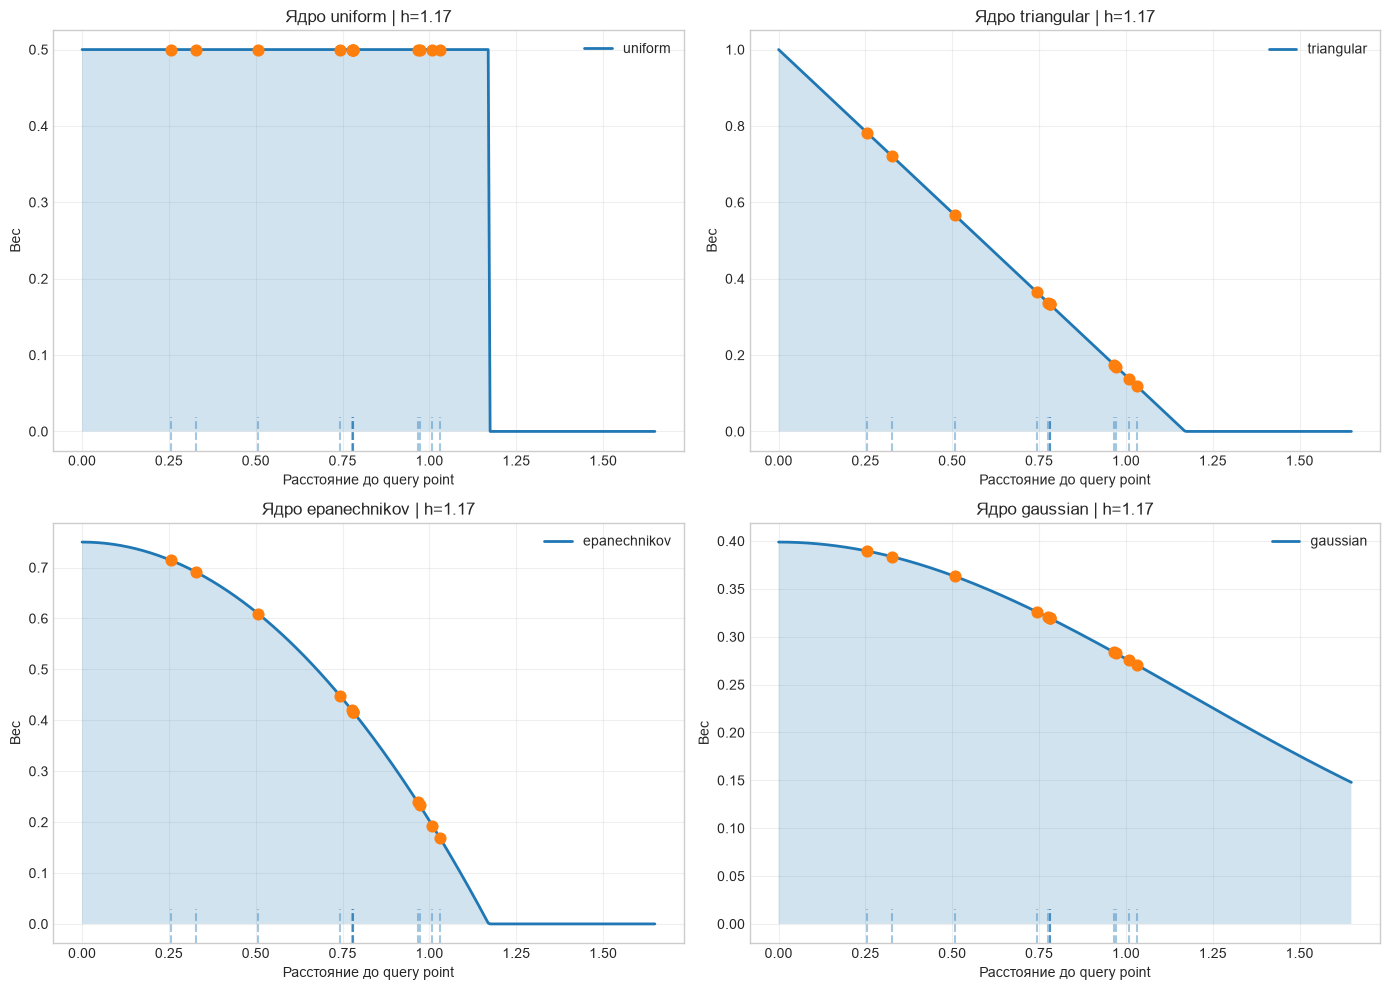

In [18]:
query_point = X_test[0]
euclidean_distances = np.linalg.norm(X_train - query_point, axis=1)
nearest_distances = np.sort(euclidean_distances)[:12]

kernel_map = {
    'uniform': uniform_kernel,
    'triangular': triangular_kernel,
    'epanechnikov': epanechnikov_kernel,
    'gaussian': gaussian_kernel
}

h_demo = np.median(nearest_distances) * 1.5
distance_grid = np.linspace(0, max(nearest_distances) * 1.6, 300)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, (name, kernel_func) in zip(axes, kernel_map.items()):
    weight_curve = np.array([kernel_func(d / h_demo) for d in distance_grid])
    ax.plot(distance_grid, weight_curve, linewidth=2, label=f'{name}')
    ax.fill_between(distance_grid, weight_curve, alpha=0.2)

    for d in nearest_distances:
        ax.axvline(d, ymin=0, ymax=0.08, linestyle='--', alpha=0.4)

    sample_weights = np.array([kernel_func(d / h_demo) for d in nearest_distances])
    ax.scatter(nearest_distances, sample_weights, s=60, zorder=3)

    ax.set_title(f'Ядро {name} | h={h_demo:.2f}')
    ax.set_xlabel('Расстояние до query point')
    ax.set_ylabel('Вес')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


<a id="parzen"></a>
### 3.2. Окна Парзена: локальная оценка плотности

Как ширина окна влияет на локальность оценки плотности: что произойдёт при слишком маленьком и слишком большом `h`?


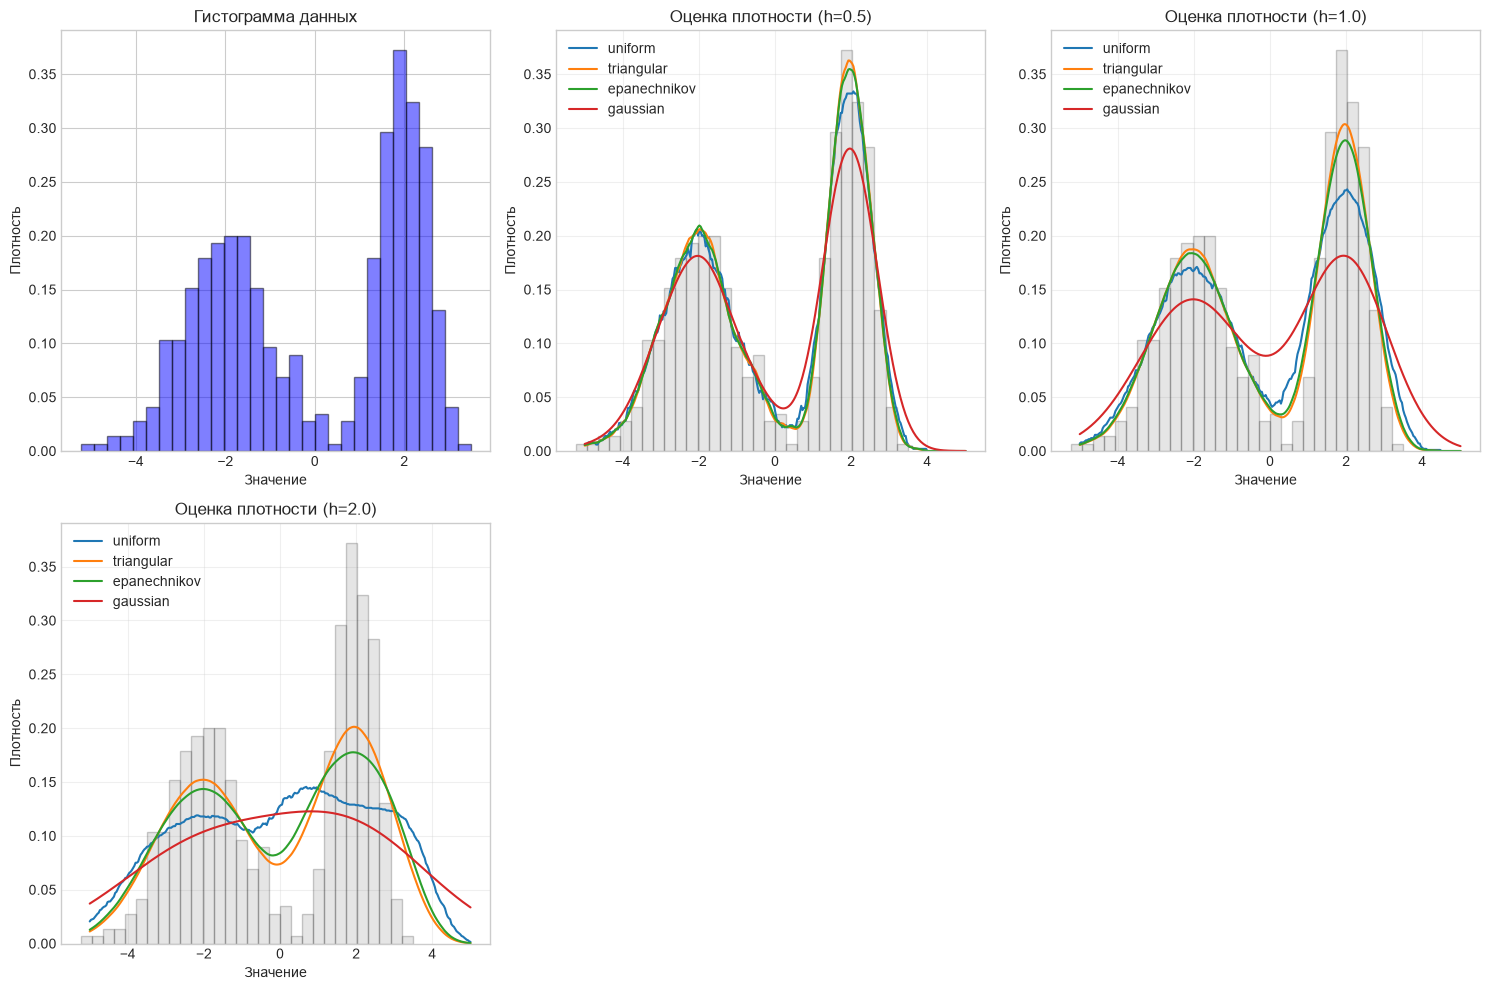

In [ ]:
class ParzenWindowDensity:
    def __init__(self, h=1.0, kernel='gaussian'):
        self.h = h
        self.kernel_name = kernel
        self.X_train = None

        if kernel == 'uniform':
            self.kernel = uniform_kernel
        elif kernel == 'triangular':
            self.kernel = triangular_kernel
        elif kernel == 'epanechnikov':
            self.kernel = epanechnikov_kernel
        elif kernel == 'gaussian':
            self.kernel = gaussian_kernel

    def fit(self, X):
        self.X_train = X
        return self

    def predict_density(self, X):
        n = len(self.X_train)
        densities = []

        for x in X:
            kernel_sum = 0
            for x_train in self.X_train:
                kernel_sum += self.kernel(u)

            density = kernel_sum / (n * self.h)
            densities.append(density)

        return np.asarray(densities, dtype=float)

np.random.seed(123)
n_samples = 500

data1 = np.random.normal(loc=-2, scale=1, size=n_samples//2)
data2 = np.random.normal(loc=2, scale=0.5, size=n_samples//2)
data = np.concatenate([data1, data2])

x_test = np.linspace(-5, 5, 300)

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.hist(data, bins=30, density=True, alpha=0.5, color='blue', edgecolor='black')
plt.title('Гистограмма данных')
plt.xlabel('Значение')
plt.ylabel('Плотность')

kernels = ['uniform', 'triangular', 'epanechnikov', 'gaussian']
bandwidths = [0.5, 1.0, 2.0]

for i, h in enumerate(bandwidths, 2):
    plt.subplot(2, 3, i)

    for kernel in kernels:
        pw = ParzenWindowDensity(h=h, kernel=kernel)
        pw.fit(data.reshape(-1, 1))
        density = pw.predict_density(x_test.reshape(-1, 1))
        plt.plot(x_test, density, label=f'{kernel}')

    plt.hist(data, bins=30, density=True, alpha=0.2, color='gray', edgecolor='black')
    plt.title(f'Оценка плотности (h={h})')
    plt.xlabel('Значение')
    plt.ylabel('Плотность')
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<a id="kernel-classification"></a>
### 3.3. Ядерная классификация

Вместо жёсткого выбора `k` соседей учитываем объекты с весами, зависящими от расстояния.


Точность ядерного классификатора: 0.8333


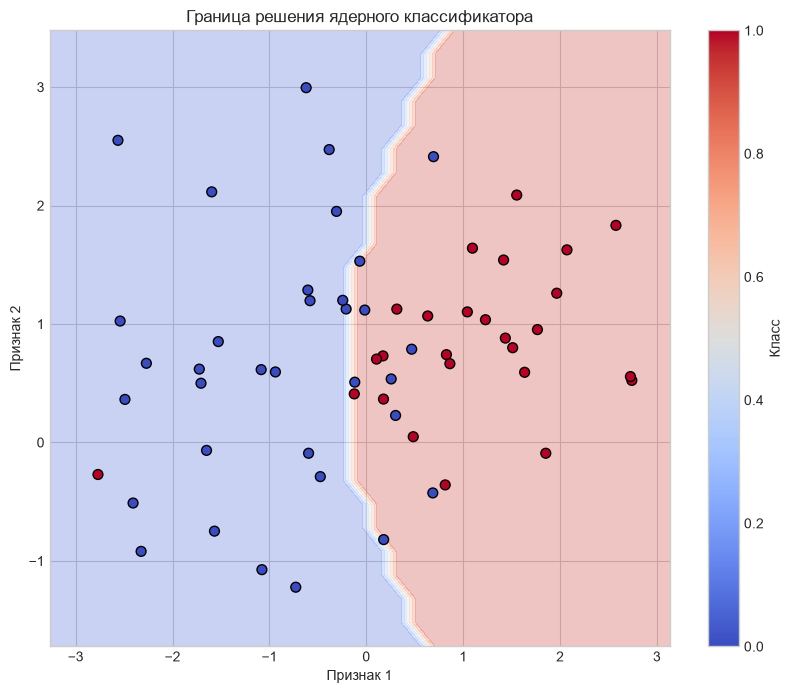

In [20]:
class KernelClassifier:
    def __init__(self, h=1.0, kernel='gaussian'):
        self.h = h
        self.kernel_name = kernel
        self.X_train = None
        self.y_train = None
        self.classes = None

        if kernel == 'uniform':
            self.kernel = uniform_kernel
        elif kernel == 'triangular':
            self.kernel = triangular_kernel
        elif kernel == 'epanechnikov':
            self.kernel = epanechnikov_kernel
        elif kernel == 'gaussian':
            self.kernel = gaussian_kernel

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        self.classes = np.unique(y)
        return self

    def predict(self, X):
        predictions = []

        for x in X:
            class_scores = {}

            for c in self.classes:
                class_indices = np.where(self.y_train == c)[0]
                class_points = self.X_train[class_indices]

                kernel_sum = 0
                for point in class_points:
                    distance = np.linalg.norm(x - point)
                    u = distance / self.h
                    kernel_sum += self.kernel(u)

                class_scores[c] = kernel_sum

            predicted_class = max(class_scores, key=class_scores.get)
            predictions.append(predicted_class)

        return np.array(predictions)

kernel_clf = KernelClassifier(h=1.0, kernel='gaussian')
kernel_clf.fit(X_train, y_train)
y_pred_kernel = kernel_clf.predict(X_test)

accuracy_kernel = accuracy_score(y_test, y_pred_kernel)
print(f"Точность ядерного классификатора: {accuracy_kernel:.4f}")

plot_decision_boundary(kernel_clf, X_test, y_test, title="Граница решения ядерного классификатора", grid_step=0.20)

<a id="local-regression"></a>
## 4. Локальная регрессия

Если в классификации соседи голосуют классами, что естественно сделать с их числовыми `y` в регрессии?


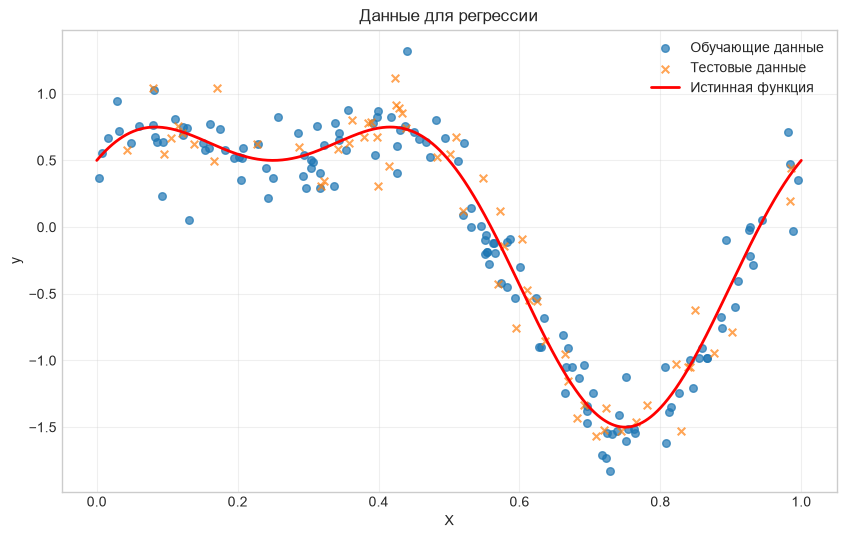

In [21]:
np.random.seed(123)
n_samples = 200

def true_function(x):
    return np.sin(2 * np.pi * x) + 0.5 * np.cos(4 * np.pi * x)

X_reg = np.sort(np.random.uniform(0, 1, n_samples)).reshape(-1, 1)
y_reg = true_function(X_reg).ravel() + np.random.normal(0, 0.2, n_samples)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42
)

plt.figure(figsize=(10, 6))
x_plot = np.linspace(0, 1, 1000).reshape(-1, 1)
y_true = true_function(x_plot)

plt.scatter(X_train_reg, y_train_reg, alpha=0.7, label='Обучающие данные', s=30)
plt.scatter(X_test_reg, y_test_reg, alpha=0.7, label='Тестовые данные', s=30, marker='x')
plt.plot(x_plot, y_true, 'r-', linewidth=2, label='Истинная функция')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Данные для регрессии')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<a id="knn-regression"></a>
### 4.1. kNN-регрессия
Тот же принцип, но вместо голосования берём среднее значений у ближайших соседей.


k= 1, MSE=0.0661
k= 5, MSE=0.0455
k=200, MSE=0.7332


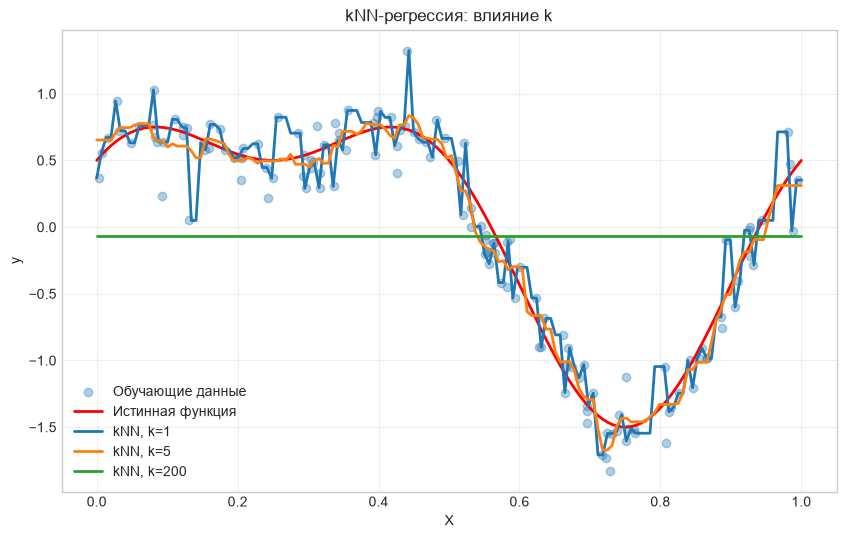

MSE sklearn (k=5): 0.0455


In [34]:
class KNNRegressor:
    def __init__(self, k=5, distance_metric='euclidean'):
        self.k = k
        self.distance_metric = distance_metric
        self.X_train = None
        self.y_train = None

    def _compute_distance(self, x1, x2):
        if self.distance_metric == 'euclidean':
            return minkowski_distance(x1, x2, p=2)
        elif self.distance_metric == 'manhattan':
            return minkowski_distance(x1, x2, p=1)

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        return self

    def predict(self, X):
        predictions = []

        for x in X:
            distances = []
            for i, train_point in enumerate(self.X_train):
                dist = self._compute_distance(x, train_point)
                distances.append((dist, i))

            distances.sort(key=lambda z: z[0])
            nearest = [i for _, i in distances[:self.k]]
            predictions.append(np.mean(self.y_train[nearest]))

        return np.array(predictions)

for k in [1, 5, 200]:
    knn_reg = KNNRegressor(k=k)
    knn_reg.fit(X_train_reg, y_train_reg)
    y_pred = knn_reg.predict(X_test_reg)
    print(f"k={k:2d}, MSE={mean_squared_error(y_test_reg, y_pred):.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(X_train_reg, y_train_reg, alpha=0.35, label='Обучающие данные')
plt.plot(x_plot, true_function(x_plot), 'r-', linewidth=2, label='Истинная функция')

for k in [1, 5, 200]:
    model = KNNRegressor(k=k)
    model.fit(X_train_reg, y_train_reg)
    plt.plot(x_plot, model.predict(x_plot), linewidth=2, label=f'kNN, k={k}')

plt.xlabel('X')
plt.ylabel('y')
plt.title('kNN-регрессия: влияние k')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Проверка на библиотечной реализации
sklearn_reg = KNeighborsRegressor(n_neighbors=5)
sklearn_reg.fit(X_train_reg, y_train_reg)
print("MSE sklearn (k=5):", round(mean_squared_error(y_test_reg, sklearn_reg.predict(X_test_reg)), 4))


<a id="nadaraya-watson"></a>
### 4.2. Регрессия Надарая–Ватсона

Что получится, если вместо одинакового среднего дать соседям kernel weights?


MSE регрессии Надарая-Ватсона: 0.0479


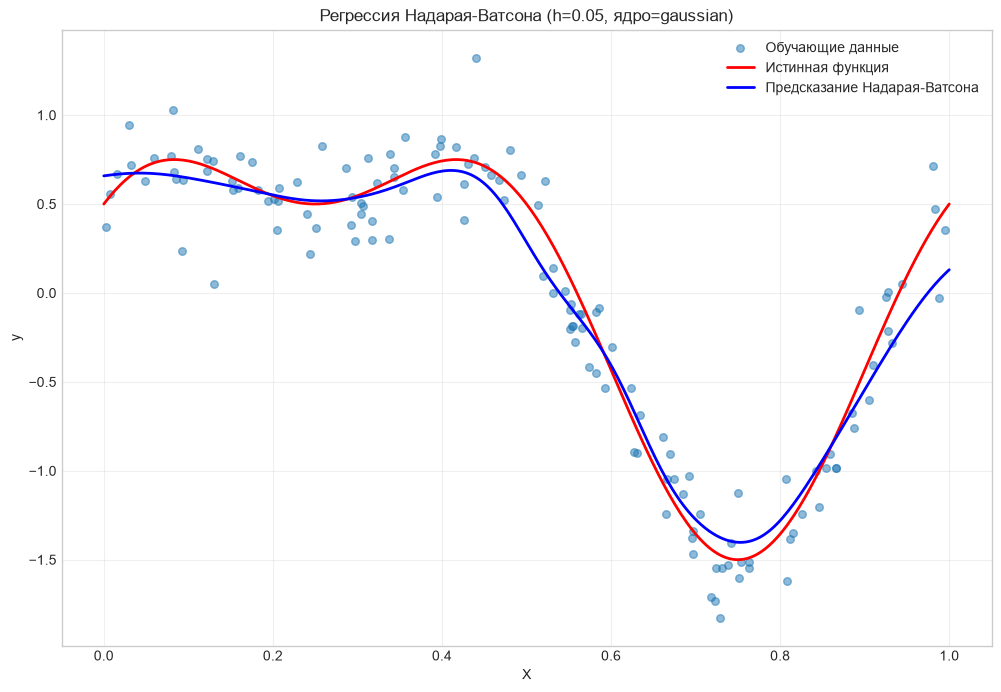

In [23]:
class NadarayaWatsonRegressor:
    def __init__(self, h=0.1, kernel='gaussian'):
        self.h = h
        self.kernel_name = kernel
        self.X_train = None
        self.y_train = None

        if kernel == 'uniform':
            self.kernel = uniform_kernel
        elif kernel == 'triangular':
            self.kernel = triangular_kernel
        elif kernel == 'epanechnikov':
            self.kernel = epanechnikov_kernel
        elif kernel == 'gaussian':
            self.kernel = gaussian_kernel

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        return self

    def predict(self, X):
        predictions = []

        for x in X:
            weights = []
            for x_train in self.X_train:
                distance = np.linalg.norm(x - x_train)
                u = distance / self.h
                weight = self.kernel(u)
                weights.append(weight)

            weights = np.array(weights)

            if np.sum(weights) == 0:
                prediction = np.mean(self.y_train)
            else:
                prediction = np.sum(weights * self.y_train) / np.sum(weights)

            predictions.append(prediction)

        return np.array(predictions)

nw_reg = NadarayaWatsonRegressor(h=0.05, kernel='gaussian')
nw_reg.fit(X_train_reg, y_train_reg)
y_pred_nw = nw_reg.predict(X_test_reg)

mse_nw = mean_squared_error(y_test_reg, y_pred_nw)
print(f"MSE регрессии Надарая-Ватсона: {mse_nw:.4f}")

plt.figure(figsize=(12, 8))

x_plot = np.linspace(0, 1, 300).reshape(-1, 1)
y_pred_plot = nw_reg.predict(x_plot)

plt.scatter(X_train_reg, y_train_reg, alpha=0.5, label='Обучающие данные', s=30)
plt.plot(x_plot, true_function(x_plot), 'r-', linewidth=2, label='Истинная функция')
plt.plot(x_plot, y_pred_plot, 'b-', linewidth=2, label='Предсказание Надарая-Ватсона')
plt.xlabel('X')
plt.ylabel('y')
plt.title(f'Регрессия Надарая-Ватсона (h={nw_reg.h}, ядро={nw_reg.kernel_name})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<a id="bandwidth"></a>
### 4.3. Ширина окна `h` как параметр сложности

Сравните маленькое и большое `h` с маленьким и большим `k`: где выше variance, а где bias?


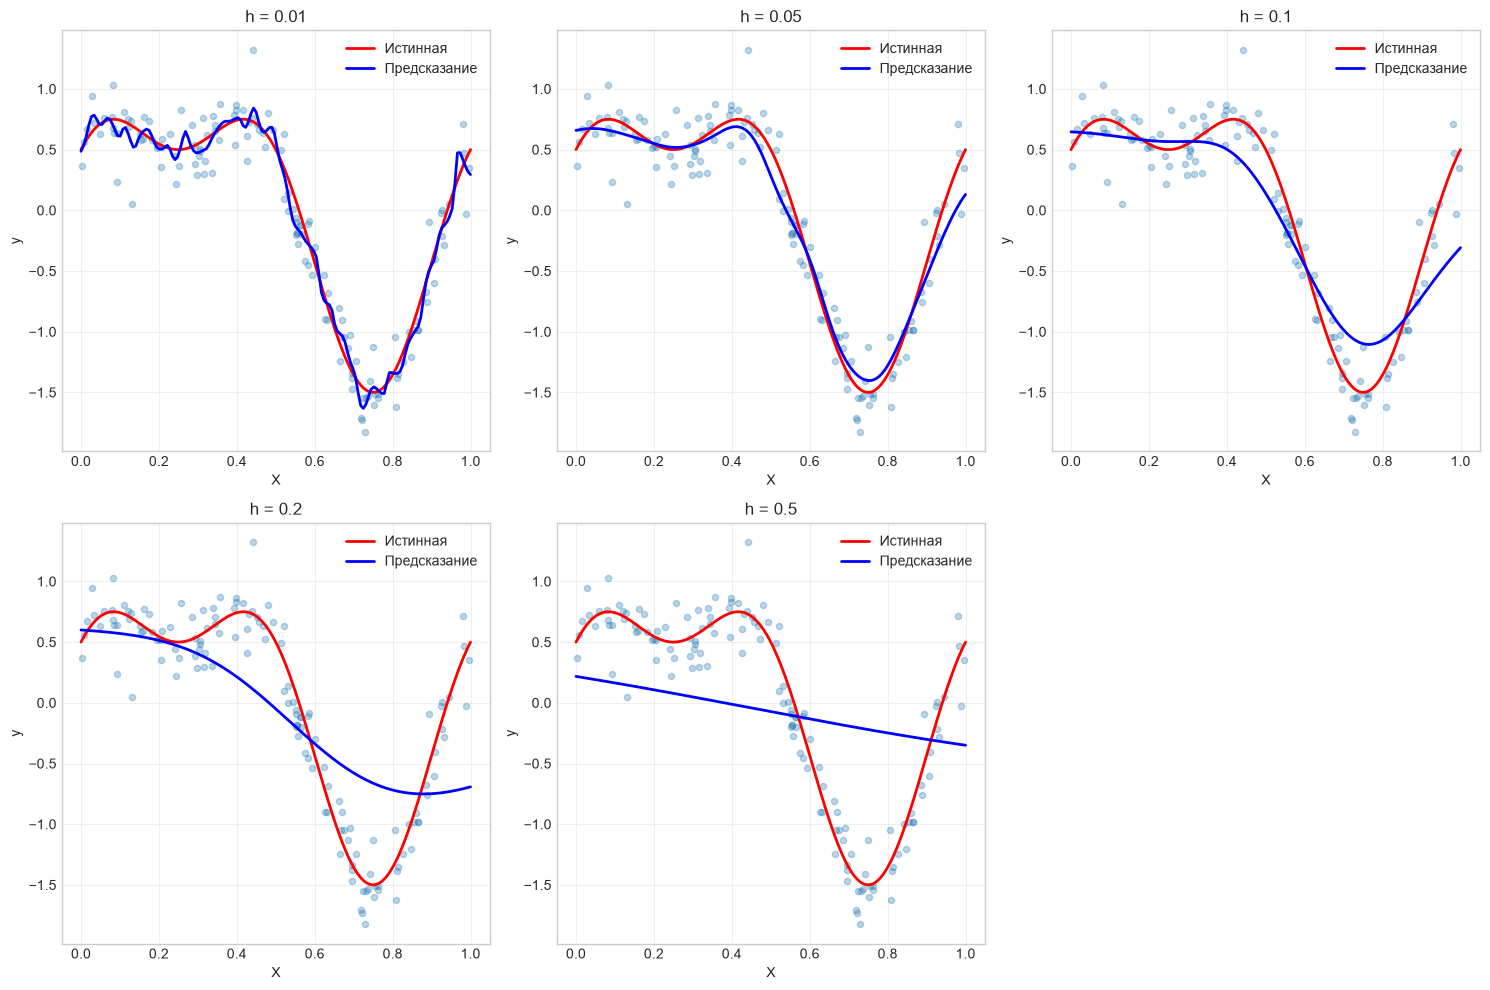

In [24]:
h_values = [0.01, 0.05, 0.1, 0.2, 0.5]
plt.figure(figsize=(15, 10))

for i, h in enumerate(h_values, 1):
    nw_reg = NadarayaWatsonRegressor(h=h, kernel='gaussian')
    nw_reg.fit(X_train_reg, y_train_reg)

    x_plot = np.linspace(0, 1, 150).reshape(-1, 1)
    y_pred_plot = nw_reg.predict(x_plot)

    plt.subplot(2, 3, i)
    plt.scatter(X_train_reg, y_train_reg, alpha=0.3, s=20)
    plt.plot(x_plot, true_function(x_plot), 'r-', linewidth=2, label='Истинная')
    plt.plot(x_plot, y_pred_plot, 'b-', linewidth=2, label='Предсказание')
    plt.title(f'h = {h}')
    plt.xlabel('X')
    plt.ylabel('y')
    plt.grid(True, alpha=0.3)
    plt.legend()

plt.tight_layout()
plt.show()

<a id="kernel-vs-bandwidth"></a>
#### 4.3.1. Форма ядра и ширина окна

Сравните эффект смены kernel с эффектом смены `h`: что сильнее меняет результат?


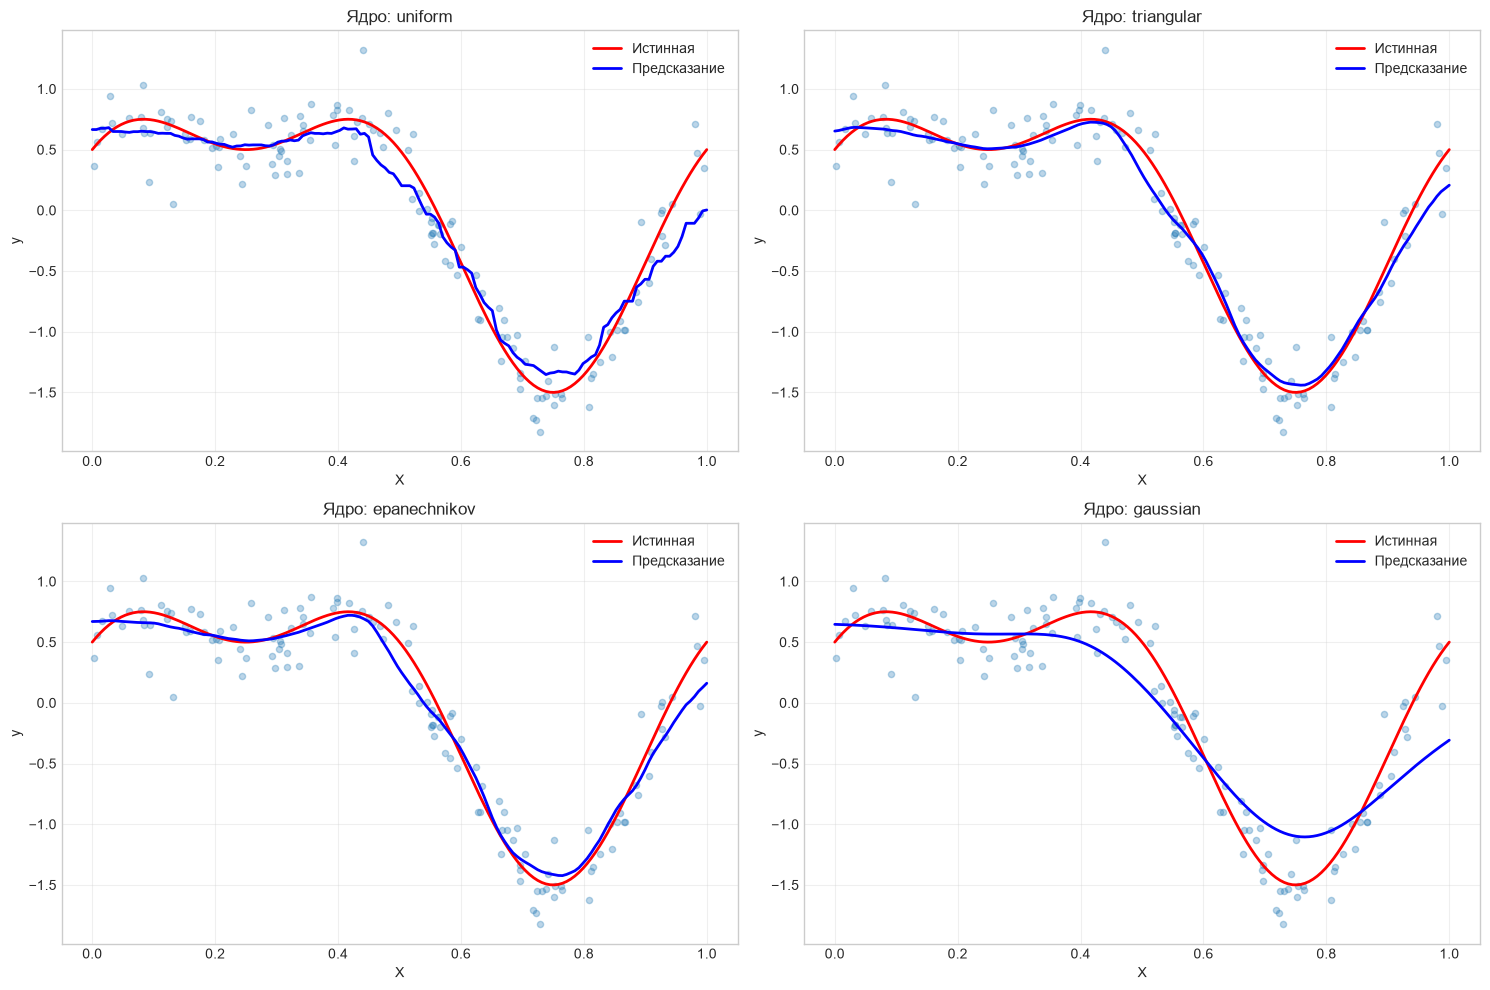

In [25]:
kernels = ['uniform', 'triangular', 'epanechnikov', 'gaussian']
h = 0.1

plt.figure(figsize=(15, 10))

for i, kernel in enumerate(kernels, 1):
    nw_reg = NadarayaWatsonRegressor(h=h, kernel=kernel)
    nw_reg.fit(X_train_reg, y_train_reg)

    x_plot = np.linspace(0, 1, 150).reshape(-1, 1)
    y_pred_plot = nw_reg.predict(x_plot)

    plt.subplot(2, 2, i)
    plt.scatter(X_train_reg, y_train_reg, alpha=0.3, s=20)
    plt.plot(x_plot, true_function(x_plot), 'r-', linewidth=2, label='Истинная')
    plt.plot(x_plot, y_pred_plot, 'b-', linewidth=2, label='Предсказание')
    plt.title(f'Ядро: {kernel}')
    plt.xlabel('X')
    plt.ylabel('y')
    plt.grid(True, alpha=0.3)
    plt.legend()

plt.tight_layout()
plt.show()

<a id="bandwidth-selection"></a>
### 4.4. Подбор `h` по validation

Теперь выберем bandwidth по validation, а test оставим только для финальной оценки.


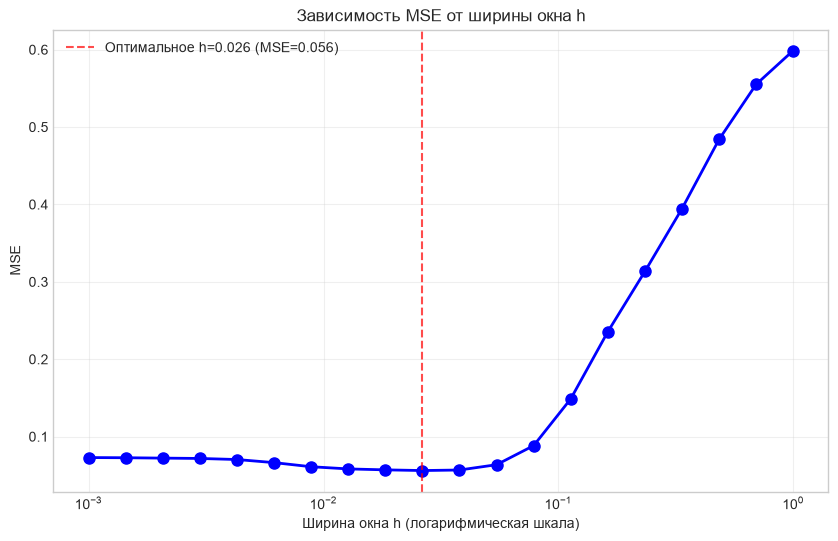

Оптимальная ширина окна: 0.0264
MSE при оптимальном h: 0.0561
MSE на тестовой выборке с оптимальным h: 0.0418


In [26]:
def evaluate_bandwidth(X_train, y_train, X_val, y_val, h_values, kernel='gaussian'):
    mse_scores = []

    for h in h_values:
        nw_reg = NadarayaWatsonRegressor(h=h, kernel=kernel)
        nw_reg.fit(X_train, y_train)
        y_pred = nw_reg.predict(X_val)
        mse = mean_squared_error(y_val, y_pred)
        mse_scores.append(mse)

    return mse_scores

X_train_temp, X_val, y_train_temp, y_val = train_test_split(
    X_train_reg, y_train_reg, test_size=0.3, random_state=42
)

h_values = np.logspace(-3, 0, 20)
mse_scores = evaluate_bandwidth(X_train_temp, y_train_temp, X_val, y_val, h_values)

plt.figure(figsize=(10, 6))
plt.plot(h_values, mse_scores, 'bo-', linewidth=2, markersize=8)
plt.xscale('log')
plt.xlabel('Ширина окна h (логарифмическая шкала)')
plt.ylabel('MSE')
plt.title('Зависимость MSE от ширины окна h')
plt.grid(True, alpha=0.3)

optimal_h_idx = np.argmin(mse_scores)
optimal_h = h_values[optimal_h_idx]
optimal_mse = mse_scores[optimal_h_idx]
plt.axvline(x=optimal_h, color='r', linestyle='--', alpha=0.7,
            label=f'Оптимальное h={optimal_h:.3f} (MSE={optimal_mse:.3f})')
plt.legend()
plt.show()

print(f"Оптимальная ширина окна: {optimal_h:.4f}")
print(f"MSE при оптимальном h: {optimal_mse:.4f}")

nw_optimal = NadarayaWatsonRegressor(h=optimal_h, kernel='gaussian')
nw_optimal.fit(X_train_reg, y_train_reg)
y_pred_optimal = nw_optimal.predict(X_test_reg)
mse_test = mean_squared_error(y_test_reg, y_pred_optimal)
print(f"MSE на тестовой выборке с оптимальным h: {mse_test:.4f}")

<a id="lowess"></a>
### 4.5. LOWESS: локальная линейная регрессия
Локальное сглаживание с локальной линейной моделью. Сделаем простую реализацию и посмотрим на результат.


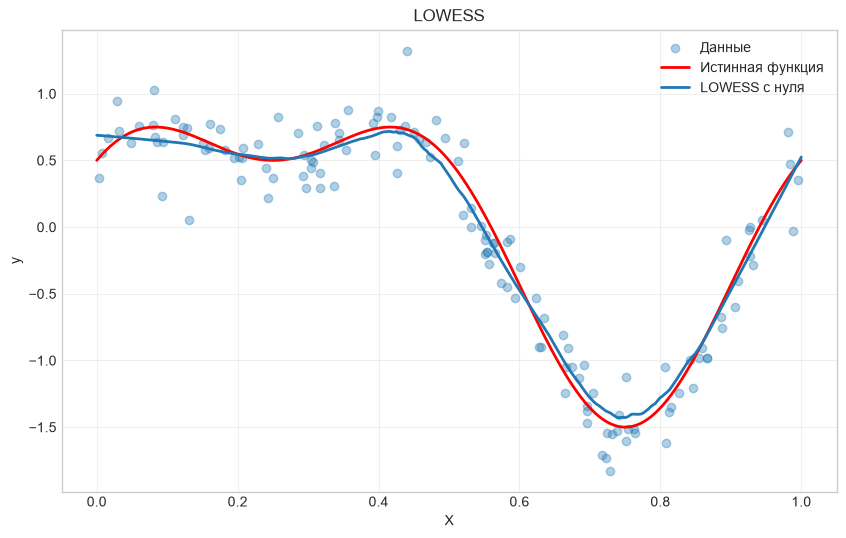

In [27]:
def tricube_kernel(u):
    u = np.abs(u)
    return (1 - u**3)**3 if u < 1 else 0


def lowess_predict(X_train, y_train, X_query, frac=0.25):
    X_train = np.asarray(X_train).ravel()
    y_train = np.asarray(y_train).ravel()
    X_query = np.asarray(X_query).ravel()

    n_neighbors = max(2, int(np.ceil(frac * len(X_train))))
    predictions = []

    for x0 in X_query:
        distances = np.abs(X_train - x0)
        h = np.partition(distances, n_neighbors - 1)[n_neighbors - 1]
        h = max(h, 1e-12)

        weights = np.array([
            tricube_kernel(d / h) for d in distances
        ])

        X_local = np.column_stack([np.ones(len(X_train)), X_train - x0])
        W = np.diag(weights)

        beta = np.linalg.pinv(X_local.T @ W @ X_local) @ (X_local.T @ W @ y_train)
        predictions.append(beta[0])

    return np.array(predictions)

x_lowess = np.linspace(0, 1, 300)
y_lowess = lowess_predict(X_train_reg, y_train_reg, x_lowess, frac=0.25)

plt.figure(figsize=(10, 6))
plt.scatter(X_train_reg, y_train_reg, alpha=0.35, label='Данные')
plt.plot(x_lowess, true_function(x_lowess), 'r-', linewidth=2, label='Истинная функция')
plt.plot(x_lowess, y_lowess, linewidth=2, label='LOWESS с нуля')
plt.xlabel('X')
plt.ylabel('y')
plt.title('LOWESS')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [28]:
# При наличии statsmodels можно сравнить с готовой реализацией
try:
    from statsmodels.nonparametric.smoothers_lowess import lowess

    lowess_sklearn_style = lowess(y_train_reg, X_train_reg.ravel(), frac=0.25, return_sorted=True)

    plt.figure(figsize=(10, 6))
    plt.scatter(X_train_reg, y_train_reg, alpha=0.25, label='Данные')
    plt.plot(x_lowess, y_lowess, linewidth=2, label='Наша реализация')
    plt.plot(lowess_sklearn_style[:, 0], lowess_sklearn_style[:, 1], '--', linewidth=2,
             label='statsmodels')
    plt.xlabel('X')
    plt.ylabel('y')
    plt.title('Сравнение LOWESS')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
except ImportError:
    print('statsmodels не установлен — сравнение пропущено.')


statsmodels не установлен — сравнение пропущено.


<a id="imbalance"></a>
## 5. Дисбаланс классов и очистка границы

### 5.1. SMOTE: синтетическое расширение minority-класса

Почему простое копирование minority points хуже идеи генерировать новые точки между соседями редкого класса?


Исходное распределение классов: [180  20]
Распределение классов после SMOTE: [180 120]


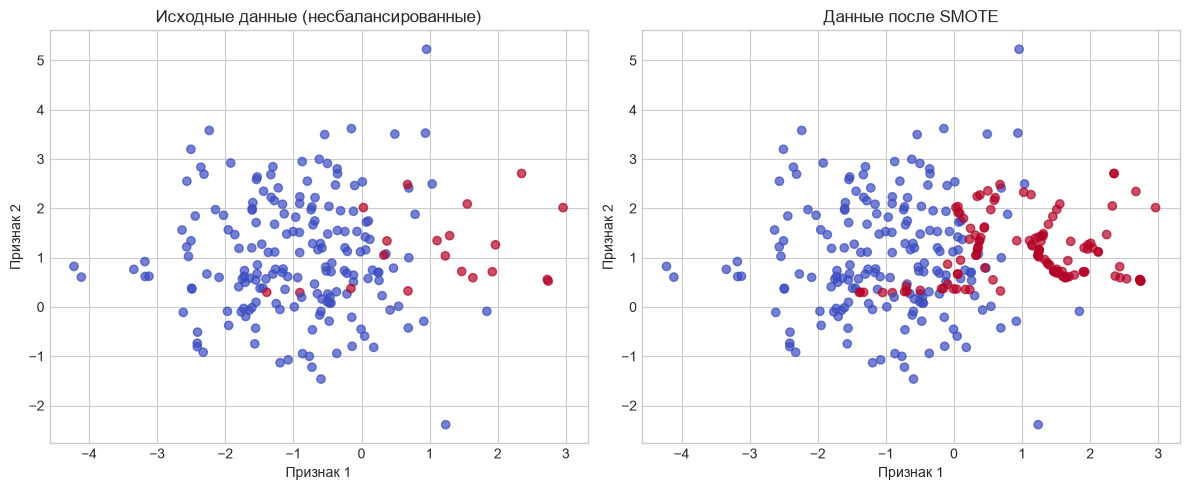

In [29]:
def simple_smote(X, y, target_class, n_samples, k=5, return_metadata=False):
    """Генерирует SMOTE-точки и при необходимости возвращает их происхождение.

    По умолчанию возвращает (X_new, y_new). При return_metadata=True
    добавляет список словарей с source_index, neighbor_index и alpha.
    Индексы относятся к исходному X; порядок записей совпадает с порядком
    синтетических точек в X_new[len(X):]. Для каждой записи:
    new_point = X[source_index] + alpha * (X[neighbor_index] - X[source_index]).
    """
    if k < 1:
        raise ValueError("k должно быть не меньше 1")
    if n_samples < 0:
        raise ValueError("n_samples должно быть неотрицательным")

    target_indices = np.where(y == target_class)[0]
    X_target = X[target_indices]
    generation_metadata = []

    if len(X_target) < 2 or n_samples == 0:
        if return_metadata:
            return X, y, generation_metadata
        return X, y

    knn = KNNClassifier(k=k)
    knn.fit(X_target, np.zeros(len(X_target)))

    synthetic_samples = []

    for _ in range(n_samples):
        idx = np.random.choice(len(X_target))
        point = X_target[idx]

        distances = []
        for i, other_point in enumerate(X_target):
            if i == idx:
                continue
            dist = minkowski_distance(point, other_point, p=2)
            distances.append((dist, i))

        distances.sort(key=lambda x: x[0])

        if len(distances) > 0:
            neighbor_idx = np.random.choice([idx for _, idx in distances[:min(k, len(distances))]])
            neighbor = X_target[neighbor_idx]

            alpha = np.random.random()
            new_point = point + alpha * (neighbor - point)
            synthetic_samples.append(new_point)
            # Сохраняем реальные исходные точки, а не ищем их после генерации.
            generation_metadata.append({
                "source_index": int(target_indices[idx]),
                "neighbor_index": int(target_indices[neighbor_idx]),
                "alpha": float(alpha),
            })

    X_new = np.vstack([X, synthetic_samples])
    y_new = np.hstack([y, np.full(len(synthetic_samples), target_class)])

    if return_metadata:
        return X_new, y_new, generation_metadata
    return X_new, y_new

X_imb, y_imb = make_classification(
    n_samples=200,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.9, 0.1],
    random_state=42
)

print(f"Исходное распределение классов: {np.bincount(y_imb)}")

X_balanced, y_balanced, smote_metadata = simple_smote(
    X_imb, y_imb, target_class=1, n_samples=100, k=3, return_metadata=True
)

print(f"Распределение классов после SMOTE: {np.bincount(y_balanced)}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_imb[:, 0], X_imb[:, 1], c=y_imb, cmap='coolwarm', alpha=0.7)
plt.title('Исходные данные (несбалансированные)')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')

plt.subplot(1, 2, 2)
plt.scatter(X_balanced[:, 0], X_balanced[:, 1], c=y_balanced, cmap='coolwarm', alpha=0.7)
plt.title('Данные после SMOTE')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')

plt.tight_layout()
plt.show()

<a id="smote-visual"></a>
#### 5.1.1. Где появляются synthetic samples

Покажем новые SMOTE-точки отдельным маркером, чтобы увидеть сам механизм интерполяции.

При генерации сохраняем индексы двух исходных объектов и коэффициент `alpha`. Для первых 20 синтетических точек пунктиром показаны отрезки между **реальными парами генерации**: каждая новая точка лежит на своём отрезке и вычисляется как `point + alpha * (neighbor - point)`. Остальные синтетические точки показаны без отрезков, чтобы не перегружать график.


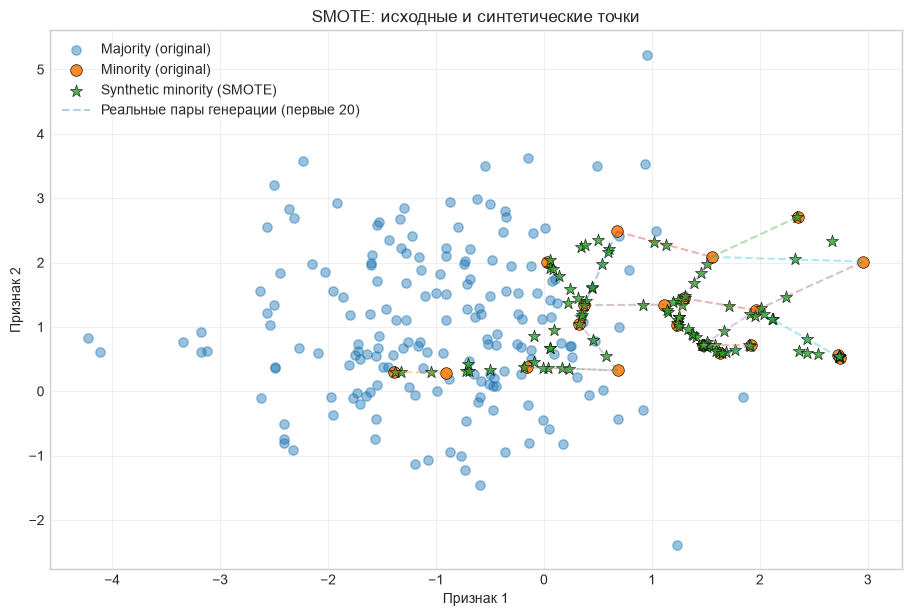

In [30]:
n_original = len(X_imb)
X_synth = X_balanced[n_original:]

minority_mask = y_imb == 1
majority_mask = y_imb == 0

plt.figure(figsize=(11, 7))
plt.scatter(X_imb[majority_mask, 0], X_imb[majority_mask, 1],
            alpha=0.45, s=45, label='Majority (original)')
plt.scatter(X_imb[minority_mask, 0], X_imb[minority_mask, 1],
            alpha=0.9, s=70, marker='o', edgecolors='k', linewidths=0.5,
            label='Minority (original)')
plt.scatter(X_synth[:, 0], X_synth[:, 1],
            alpha=0.8, s=85, marker='*', edgecolors='k', linewidths=0.5,
            label='Synthetic minority (SMOTE)')

# Берём реальные пары из метаданных, сохранённых при генерации SMOTE.
for pair_number, (new_pt, metadata) in enumerate(zip(X_synth[:20], smote_metadata[:20])):
    point = X_imb[metadata["source_index"]]
    neighbor = X_imb[metadata["neighbor_index"]]
    plt.plot(
        [point[0], new_pt[0], neighbor[0]],
        [point[1], new_pt[1], neighbor[1]],
        linestyle='--', alpha=0.35,
        label='Реальные пары генерации (первые 20)' if pair_number == 0 else None
    )

plt.title('SMOTE: исходные и синтетические точки')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


<a id="tomek"></a>
### 5.2. Tomek Links: поиск пограничных пар

Какие взаимно ближайшие объекты разных классов выглядят как кандидаты на очистку границы?


Найдено связей Томека: 5


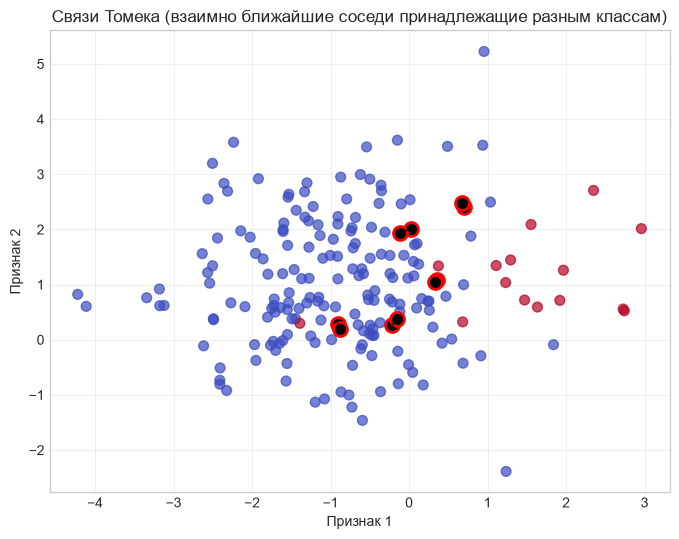

In [31]:
def find_tomek_links(X, y):
    tomek_links = []

    for i in range(len(X)):
        min_distance = float('inf')
        nearest_idx = -1

        for j in range(len(X)):
            if i == j:
                continue

            distance = minkowski_distance(X[i], X[j], p=2)
            if distance < min_distance:
                min_distance = distance
                nearest_idx = j

        if nearest_idx != -1 and y[nearest_idx] != y[i]:
            min_distance_j = float('inf')
            nearest_idx_j = -1

            for k in range(len(X)):
                if k == nearest_idx:
                    continue

                distance = minkowski_distance(X[nearest_idx], X[k], p=2)
                if distance < min_distance_j:
                    min_distance_j = distance
                    nearest_idx_j = k

            if nearest_idx_j == i:
                pair = tuple(sorted([i, nearest_idx]))
                if pair not in tomek_links:
                    tomek_links.append(pair)

    return tomek_links

tomek_links = find_tomek_links(X_imb, y_imb)
print(f"Найдено связей Томека: {len(tomek_links)}")

plt.figure(figsize=(8, 6))
plt.scatter(X_imb[:, 0], X_imb[:, 1], c=y_imb, cmap='coolwarm', alpha=0.7, s=50)

for i, j in tomek_links:
    plt.plot([X_imb[i, 0], X_imb[j, 0]],
             [X_imb[i, 1], X_imb[j, 1]],
             'k-', linewidth=2, alpha=0.5)
    plt.scatter([X_imb[i, 0], X_imb[j, 0]],
                [X_imb[i, 1], X_imb[j, 1]],
                c='black', s=100, marker='o', edgecolors='red', linewidths=2)

plt.title('Связи Томека (взаимно ближайшие соседи принадлежащие разным классам)')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.grid(True, alpha=0.3)
plt.show()

<a id="tomek-cleanup"></a>
### 5.3. Tomek Links: очистка мажоритарного класса
В лекции рассматривается несколько стратегий. Ниже — одна из самых простых: удаляем объект мажоритарного класса из каждой связи.


Удалено объектов мажоритарного класса: 5
Размер выборки: 200 -> 195


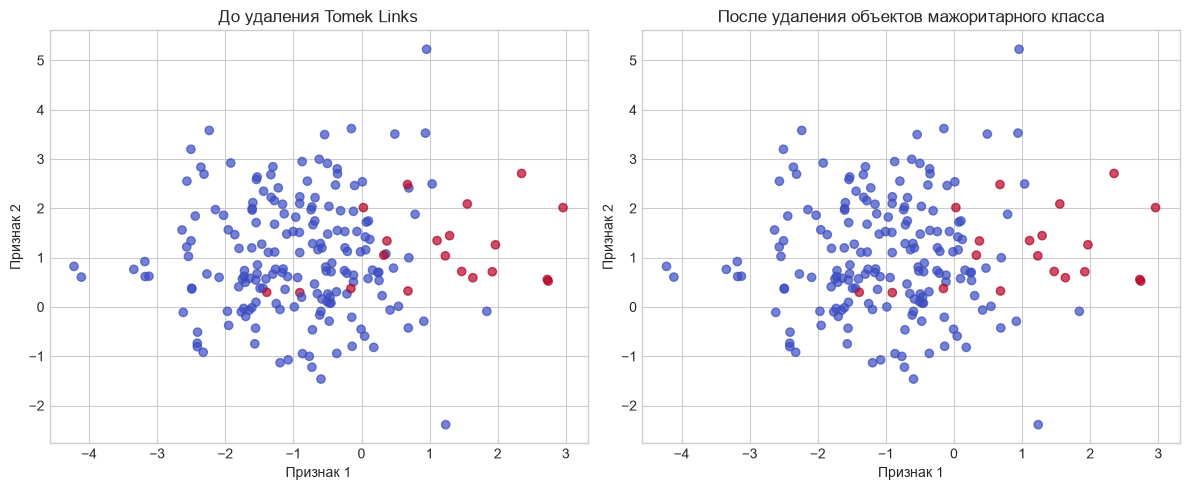

In [32]:
def remove_majority_tomek_links(X, y, tomek_links):
    classes, counts = np.unique(y, return_counts=True)
    majority_class = classes[np.argmax(counts)]

    remove_indices = set()
    for i, j in tomek_links:
        if y[i] == majority_class:
            remove_indices.add(i)
        if y[j] == majority_class:
            remove_indices.add(j)

    keep = [i for i in range(len(X)) if i not in remove_indices]
    return X[keep], y[keep], sorted(remove_indices)

X_clean, y_clean, removed = remove_majority_tomek_links(X_imb, y_imb, tomek_links)

print(f"Удалено объектов мажоритарного класса: {len(removed)}")
print(f"Размер выборки: {len(X_imb)} -> {len(X_clean)}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_imb[:, 0], X_imb[:, 1], c=y_imb, cmap='coolwarm', alpha=0.7)
plt.title('До удаления Tomek Links')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')

plt.subplot(1, 2, 2)
plt.scatter(X_clean[:, 0], X_clean[:, 1], c=y_clean, cmap='coolwarm', alpha=0.7)
plt.title('После удаления объектов мажоритарного класса')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')

plt.tight_layout()
plt.show()


<a id="smote-tomek"></a>
### 5.4. SMOTE + Tomek Links
Хороший финальный эксперимент: сначала добавляем точки для меньшего класса, затем убираем неоднозначные пограничные пары.


После SMOTE: 300 объектов
Tomek Links после SMOTE: 6
После удаления: 294 объектов


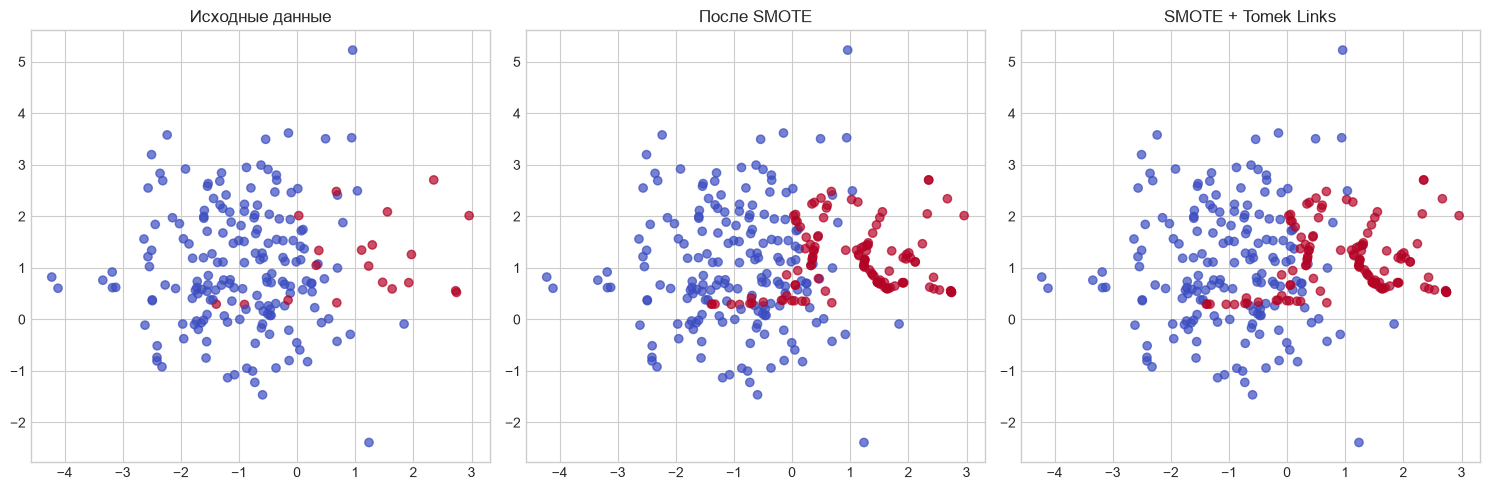

In [33]:
tomek_after_smote = find_tomek_links(X_balanced, y_balanced)
X_smote_clean, y_smote_clean, removed_smote = remove_majority_tomek_links(
    X_balanced, y_balanced, tomek_after_smote
)

print(f"После SMOTE: {len(X_balanced)} объектов")
print(f"Tomek Links после SMOTE: {len(tomek_after_smote)}")
print(f"После удаления: {len(X_smote_clean)} объектов")

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(X_imb[:, 0], X_imb[:, 1], c=y_imb, cmap='coolwarm', alpha=0.7)
plt.title('Исходные данные')

plt.subplot(1, 3, 2)
plt.scatter(X_balanced[:, 0], X_balanced[:, 1], c=y_balanced, cmap='coolwarm', alpha=0.7)
plt.title('После SMOTE')

plt.subplot(1, 3, 3)
plt.scatter(X_smote_clean[:, 0], X_smote_clean[:, 1], c=y_smote_clean,
            cmap='coolwarm', alpha=0.7)
plt.title('SMOTE + Tomek Links')

plt.tight_layout()
plt.show()


<a id="homework"></a>
## 6. Домашняя практика

### 6.1. Задания на выбор


1. KD-дерево для ускорения kNN

Реализовать собственное KD-дерево: рекурсивно разбивать пространство по координатным осям, а при запросе просматривать только те ветви, которые могут содержать ближайших соседей. Сравнить количество вычисляемых расстояний и время работы с полным перебором и проверить, при какой размерности преимущество KD-дерева начинает исчезать.

2. Ball-дерево

Реализовать упрощённое Ball-дерево, в котором каждый узел хранит центр и радиус шара, а поиск использует неравенство треугольника для отсечения заведомо ненужных поддеревьев. Сравнить Ball-tree с KD-tree на данных разной размерности и объяснить экспериментально, почему разбиение на шары может быть удобнее координатных разбиений.

3. HNSW: граф ближайших соседей *

Реализовать небольшую учебную версию HNSW на двумерных или низкоразмерных данных: построить граф ближайших соседей и выполнять поиск, переходя от текущей вершины к более близким вершинам вместо полного перебора. Для упрощения можно сначала сделать одноуровневый NSW-граф, а затем добавить второй уровень и сравнить скорость при разных значениях числа рёбер и глубины поиска.

4. LSH для приближённого поиска

Реализовать простой вариант Locality-Sensitive Hashing: построить несколько случайных гиперплоскостей, переводить объекты в бинарные хэш-коды и искать кандидатов только в совпадающих или соседних корзинах. Исследовать, как количество хэш-таблиц и число битов влияет на количество кандидатов, время поиска.

5. IVF: поиск только в ближайших кластерах

Разбить обучающую выборку с помощью k-means на несколько кластеров и построить инвертированный список объектов для каждого кластера. При запросе сначала находить ближайшие центроиды, а затем выполнять обычный kNN только внутри нескольких соответствующих кластеров; сравнить влияние параметров на скорость и точность.

6. VP-tree как альтернативное метрическое дерево

Реализовать Vantage-Point Tree, которое делит объекты не по координатам, а по расстоянию до выбранной опорной точки и медиане этих расстояний. Проверить, как такой подход работает с разными метриками, в том числе с теми, для которых координатное разбиение KD-дерева естественно не подходит.


<a id="homework-rules"></a>
### 6.2. Требования к выполнению

1. Пишите код самостоятельно, руками без гпт, это для вас же будет полезно, понимания будет в разы больше, увидим гптшный код, будем придираться сильнее

2. Не вздумайте копировать код библиотечной реализации, заставим обьяснять каждую строчку!

3. Все библиотеки под баном, использовать можно только numpy(максимально рекомендуется использовать весь доступный синтаксический сахар, чтобы он вошел в привычку).

4. Если найдете, какую-то похожую оптимизацию или тему для домашней реализации, уточните у практика или семинариста, можно ли написать именно ее вместо предложенной.

5. В домашней реализации обязательно показать, наивный вариант, новый, написанный вами и их сравнение по тем, метрикам, в которых вы стали лучше.


<a id="summary"></a>
## 7. Итог
Ответьте без нового кода:

1. Почему метрика и масштаб признаков являются частью модели kNN?
2. Чем маленький `k` концептуально похож на маленький `h`?
3. Как связаны kNN regression, Nadaraya–Watson и LOWESS?
